# DSCI 552: Homework 4

- **Name:** Olivia Liau
- **GitHub username:** oliauusc
- **USC ID:** 2625431606

## 0. setup

All imports, plot settings, and shared constants live in this one code cell.

In [1]:
import io
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from scipy.stats import norm
from sklearn.exceptions import ConvergenceWarning

import statsmodels.api as sm
from statsmodels.tools.sm_exceptions import (ConvergenceWarning as SmConvergenceWarning,
                                              HessianInversionWarning,
                                              PerfectSeparationWarning)
from joblib import Parallel, delayed

from sklearn.feature_selection import RFE, VarianceThreshold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, auc, balanced_accuracy_score,
                             confusion_matrix, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize

# shared plot palette for every figure below
PINK = "#EC4899"
TEAL = "#14B8A6"
NEUTRAL = "#4B5563"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": NEUTRAL,
    "axes.labelcolor": NEUTRAL,
    "axes.titlecolor": NEUTRAL,
    "axes.grid": True,
    "grid.color": "#E5E7EB",
    "grid.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": NEUTRAL,
    "ytick.color": NEUTRAL,
    "legend.frameon": False,
    "font.size": 10,
    "axes.titlesize": 11,
    "figure.dpi": 110,
})

# fixed seed for every random step (cv shuffling, sampling, randomized solvers)
SEED = 42
# binary models: stratified 5-fold cv (the 9 bending instances spread over folds)
CV5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
# seven-class models: stratified 4-fold cv, because bending2 has exactly 4
# training rows, so every validation fold holds one bending2 instance
CV4 = StratifiedKFold(4, shuffle=True, random_state=SEED)

SERIES = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
ACTIVITIES = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
BENDING = ["bending1", "bending2"]
DATA_DIR = Path("../data/AReM")
# test split: datasets 1 and 2 of the bending folders, datasets 1 to 3 of the rest
N_TEST = {a: (2 if a.startswith("bending") else 3) for a in ACTIVITIES}

# the three statistic types homework 3 kept after its selection step (1(c)iv);
# the full set of 7 statistics below is still used wherever the handout asks
# for "time-domain features"
SELECTED_TYPES = ["mean", "std", "max"]

## 1. recap of homework 3 (not graded)

The loading, cleaning, split, and feature-extraction code is ported unchanged from
homework 3; it is repeated here so this notebook runs on its own. One addition for
this homework: `extract_features` now segments each 480-row series with
`np.array_split`, so every observation is kept and segment lengths differ by at
most one row. The three statistic types used for the plots in 2(a) are the ones
homework 3 selected in its section 1(c)iv (`SELECTED_TYPES` in the setup cell).

In [2]:
# stat name -> (column-name template, function); the template renders min1,
# max1, ..., q1_1, q3_1, ..., q3_6 for the 6 series
STATS = [
    ("min", "min{s}", np.min),
    ("max", "max{s}", np.max),
    ("mean", "mean{s}", np.mean),
    ("median", "median{s}", np.median),
    ("std", "std{s}", lambda v: np.std(v, ddof=1)),
    ("q1", "q1_{s}", lambda v: np.quantile(v, 0.25)),
    ("q3", "q3_{s}", lambda v: np.quantile(v, 0.75)),
]

ACTIVITY_DATA = {a: sorted((DATA_DIR / a).glob("*.csv")) for a in ACTIVITIES}


def load_instance(csv_path):
    # parse one csv entirely in code (the raw files are never edited):
    # skip the leading '#' comment lines, sniff the delimiter, drop trailing
    # delimiters, and interpolate any missing time steps
    lines = csv_path.read_text().splitlines()
    n_comments = sum(1 for l in lines if l.startswith("#"))
    data_lines = [l for l in lines if l.strip() and not l.startswith("#")]
    assert n_comments == 5, f"{csv_path}: expected 5 comment lines, found {n_comments}"

    fixes = []

    # a few rows end in stray characters: a tab (standing/dataset5.csv) or an
    # extra trailing comma (cycling/dataset9.csv, cycling/dataset14.csv)
    cleaned, n_space, n_comma = [], 0, 0
    for l in data_lines:
        new = l.rstrip()
        n_space += int(new != l)
        new2 = new.rstrip(",")
        n_comma += int(new2 != new)
        cleaned.append(new2)
    if n_space:
        fixes.append(f"stripped trailing whitespace on {n_space} row(s)")
    if n_comma:
        fixes.append(f"dropped trailing delimiter on {n_comma} row(s)")

    # bending2/dataset4.csv is whitespace-separated instead of comma-separated
    sep = "," if "," in cleaned[0] else r"\s+"
    kwargs = {"sep": sep, "header": None, "names": ["time"] + SERIES}
    if sep != ",":
        kwargs["engine"] = "python"
        fixes.append("parsed with whitespace delimiter instead of comma")

    df = pd.read_csv(io.StringIO("\n".join(cleaned)), **kwargs)

    # some files miss a time step (sitting/dataset8.csv lacks t = 13500 ms);
    # reindex to the full 250 ms grid and interpolate so every instance has
    # the same 480 rows
    times = df["time"].to_numpy(dtype=float)
    step = float(np.median(np.diff(times)))
    full_grid = np.arange(times[0], times[-1] + step / 2, step)
    assert df["time"].is_unique and df["time"].is_monotonic_increasing
    if len(df) < len(full_grid):
        n_missing = len(full_grid) - len(df)
        missing = ", ".join(f"{t:g}" for t in sorted(set(full_grid) - set(times)))
        df = (df.set_index("time")
                .reindex(full_grid)
                .interpolate(method="index", limit_direction="both")
                .rename_axis("time")
                .reset_index())
        fixes.append(f"linearly interpolated {n_missing} missing row(s) at t = {missing} ms")

    values = df[SERIES].to_numpy(dtype=float)
    assert values.shape == (480, 6), f"{csv_path}: unexpected shape {values.shape}"
    assert np.isfinite(values).all(), f"{csv_path}: non-finite values remain"
    activity = csv_path.parent.name
    return ({"activity": activity,
             "dataset": int(csv_path.stem.removeprefix("dataset")),
             "id": f"{activity}/{csv_path.stem}",
             "data": values}, fixes)


instances, cleaning_log = [], []
for activity in ACTIVITIES:
    for csv_path in ACTIVITY_DATA[activity]:
        inst, fixes = load_instance(csv_path)
        instances.append(inst)
        if fixes:
            cleaning_log.append({"file": f"{activity}/{csv_path.name}", "fixes": "; ".join(fixes)})

n_plain = len(instances) - len(cleaning_log)
print(f"loaded {len(instances)} instances from {DATA_DIR}/")
print("every file carries the same 5 leading '#' comment lines (skipped while parsing);")
print(f"{n_plain} files needed no other fix; {len(cleaning_log)} files were repaired in code:")
cleaning_log = pd.DataFrame(cleaning_log)
cleaning_log

loaded 88 instances from ../data/AReM/
every file carries the same 5 leading '#' comment lines (skipped while parsing);
83 files needed no other fix; 5 files were repaired in code:


,file,fixes
0,bending2/dataset4.csv,stripped trailing whitespace on 480 row(s); pa...
1,cycling/dataset14.csv,dropped trailing delimiter on 1 row(s)
2,cycling/dataset9.csv,dropped trailing delimiter on 1 row(s)
3,sitting/dataset8.csv,linearly interpolated 1 missing row(s) at t = ...
4,standing/dataset5.csv,stripped trailing whitespace on 1 row(s)


In [3]:
# test = datasets 1 and 2 of the bending folders, datasets 1 to 3 of the rest
for inst in instances:
    inst["split"] = "test" if inst["dataset"] <= N_TEST[inst["activity"]] else "train"

n_test = sum(inst["split"] == "test" for inst in instances)
n_bend_train = sum(i["activity"] in BENDING and i["split"] == "train" for i in instances)
n_bend_test = sum(i["activity"] in BENDING and i["split"] == "test" for i in instances)
train_counts = {a: sum(i["activity"] == a and i["split"] == "train" for i in instances)
                for a in ACTIVITIES}

# sanity checks; the same split as homework 3
assert len(instances) == 88
assert all(inst["data"].shape == (480, 6) for inst in instances)
assert n_test == 19 and len(instances) - n_test == 69
assert (n_bend_train, 69 - n_bend_train) == (9, 60)   # binary: bending vs other
assert (n_bend_test, n_test - n_bend_test) == (4, 15)
assert train_counts["bending1"] == 5 and train_counts["bending2"] == 4
assert all(train_counts[a] == 12 for a in ACTIVITIES if a not in BENDING)

split_summary = pd.DataFrame({
    "activity": ACTIVITIES + ["total"],
    "train": [train_counts[a] for a in ACTIVITIES] + [69],
    "test": [sum(i["activity"] == a and i["split"] == "test" for i in instances) for a in ACTIVITIES]
            + [n_test],
}).set_index("activity")
split_summary

,train,test
activity,,
bending1,5,2
bending2,4,2
cycling,12,3
lying,12,3
sitting,12,3
standing,12,3
walking,12,3
total,69,19


In [4]:
def extract_features(instances, n_segments=1):
    # summarize each (segment, series) pair with the 7 statistics above.
    # n_segments = 1 yields the 42 homework-3 columns min1 ... q3_6; larger
    # values first split every 480-row series into n_segments nearly equal
    # segments (np.array_split, so lengths sum to 480 and differ by at most 1)
    # and append _seg<k> to the column names
    rows = []
    for inst in instances:
        data = inst["data"]  # shape (480, 6)
        n_rows, n_series = data.shape
        segments = np.array_split(data, n_segments, axis=0)
        seg_lengths = [len(seg) for seg in segments]
        assert sum(seg_lengths) == n_rows, "segments must keep every observation"
        assert max(seg_lengths) - min(seg_lengths) <= 1, "segment lengths must differ by at most 1"
        feats = {}
        for seg, chunk in enumerate(segments):
            suffix = f"_seg{seg + 1}" if n_segments > 1 else ""
            for col in range(n_series):
                vals = chunk[:, col]
                for _, template, fn in STATS:
                    feats[template.format(s=col + 1) + suffix] = fn(vals)
        rows.append({"instance": inst["id"], "activity": inst["activity"], **feats})
    return pd.DataFrame(rows)


feature_cols = [t.format(s=s) for s in range(1, 7) for _, t, _ in STATS]
features = extract_features(instances)
assert features.shape == (88, 2 + 42)
assert [c for c in features.columns if c not in ("instance", "activity")] == feature_cols
assert feature_cols[0] == "min1" and feature_cols[-1] == "q3_6"
features.insert(2, "split", [inst["split"] for inst in instances])

# the same function produces the segmented features of parts 2(a)ff: check a
# few l values, including l = 7, where 480 does not divide evenly (69,69,69,69,68,68,68)
for l in (2, 3, 7, 20):
    seg = extract_features(instances[:2], n_segments=l)
    assert seg.shape == (2, 2 + 42 * l)
demo = extract_features(instances[:1], n_segments=3)
print("segmented column names look like:", [c for c in demo.columns if c.startswith("mean2")])
features.head().round(2)

segmented column names look like: ['mean2_seg1', 'mean2_seg2', 'mean2_seg3']


,instance,activity,split,min1,max1,mean1,median1,std1,q1_1,q3_1,...,std5,q1_5,q3_5,min6,max6,mean6,median6,std6,q1_6,q3_6
0,bending1/dataset1,bending1,test,37.25,45.00,40.62,40.50,1.48,39.25,42.00,...,2.19,33.00,36.00,0.0,1.92,0.57,0.43,0.58,0.0,1.30
1,bending1/dataset2,bending1,test,38.00,45.67,42.81,42.50,1.44,42.00,43.67,...,2.00,32.00,34.50,0.0,3.11,0.57,0.43,0.60,0.0,1.30
2,bending1/dataset3,bending1,train,35.00,47.40,43.95,44.33,1.56,43.00,45.00,...,2.00,35.36,36.50,0.0,1.79,0.49,0.43,0.51,0.0,0.94
3,bending1/dataset4,bending1,train,33.00,47.75,42.18,43.50,3.67,39.15,45.00,...,3.85,30.46,36.33,0.0,2.18,0.61,0.50,0.52,0.0,1.00
4,bending1/dataset5,bending1,train,33.00,45.75,41.68,41.75,2.24,41.33,42.75,...,2.41,28.46,31.25,0.0,1.79,0.38,0.43,0.39,0.0,0.50


## 2(a)i scatter matrices of the selected features

Homework 3 (section 1(c)iv) selected the statistics mean, std, and max
(`SELECTED_TYPES`). The scatter matrices below use those three statistics for
series 1, 2, and 6, on the 69 training instances only: bending in pink with
circle markers, other activities in teal with cross markers.

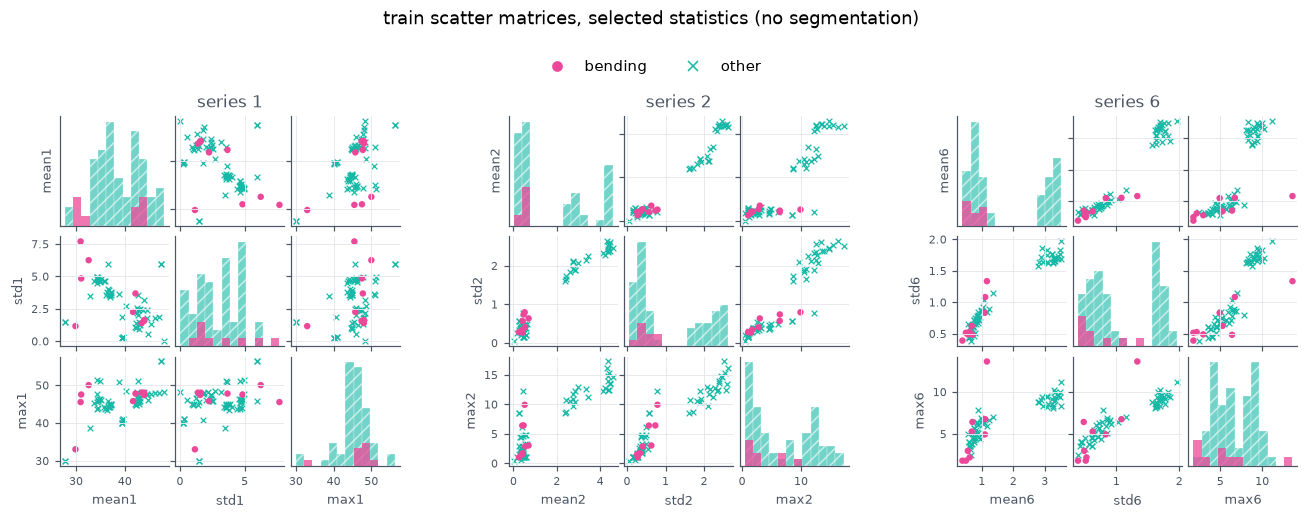

In [5]:
# binary label: 1 = bending (bending1 or bending2), 0 = other
train_instances = [i for i in instances if i["split"] == "train"]
train_features = features[features["split"] == "train"].reset_index(drop=True)
y_binary = train_features["activity"].isin(BENDING).to_numpy()
assert y_binary.sum() == 9 and (~y_binary).sum() == 60


def plot_scatter_matrix(fig, spec, cols, data, y, title, rot=0):
    # one k x k scatter matrix inside the given gridspec slot: scatter plots
    # below the diagonal, class histograms on the diagonal (bending solid
    # pink, other hatched teal so the classes also read without color)
    inner = GridSpecFromSubplotSpec(len(cols), len(cols), subplot_spec=spec,
                                    wspace=0.06, hspace=0.1)
    for i, ycol in enumerate(cols):
        for j, xcol in enumerate(cols):
            ax = fig.add_subplot(inner[i, j])
            if i == j:
                bins = np.histogram_bin_edges(data[ycol].to_numpy(), bins=12)
                ax.hist(data[ycol][~y], bins=bins, color=TEAL, alpha=0.6,
                        hatch="///", edgecolor="white", linewidth=0.3)
                ax.hist(data[ycol][y], bins=bins, color=PINK, alpha=0.75)
                ax.set_yticks([])
                ax.grid(False)
            else:
                ax.scatter(data[xcol][~y], data[ycol][~y], s=14, marker="x",
                           color=TEAL, linewidths=0.8)
                ax.scatter(data[xcol][y], data[ycol][y], s=18, marker="o",
                           color=PINK, edgecolors="none")
            if title and i == 0 and j == len(cols) // 2:
                ax.set_title(title, fontsize=11)
            if i < len(cols) - 1:
                ax.set_xticklabels([])
            else:
                ax.set_xlabel(xcol, fontsize=8.5, rotation=rot,
                              ha="right" if rot else "center")
            if j > 0:
                ax.set_yticklabels([])
            else:
                ax.set_ylabel(ycol, fontsize=8.5)
            ax.tick_params(labelsize=7.5)


legend_handles = [Line2D([0], [0], marker="o", linestyle="", color=PINK, label="bending"),
                  Line2D([0], [0], marker="x", linestyle="", color=TEAL, label="other")]

fig = plt.figure(figsize=(12.5, 4.6))
outer = GridSpec(1, 3, figure=fig, wspace=0.32, top=0.78, bottom=0.09, left=0.07, right=0.97)
for k, s in enumerate((1, 2, 6)):
    plot_scatter_matrix(fig, outer[k], [f"{t}{s}" for t in SELECTED_TYPES],
                        train_features, y_binary, f"series {s}")
fig.suptitle("train scatter matrices, selected statistics (no segmentation)", y=0.99)
fig.legend(handles=legend_handles, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 0.92))
plt.show()

## 2(a)ii scatter matrices with two segments

Every series is split into two halves (`n_segments = 2`), so each series gets six
columns: the three selected statistics for segment 1 and for segment 2. The
matrices again use the 69 training instances only, one larger figure per series
so the labels stay legible.

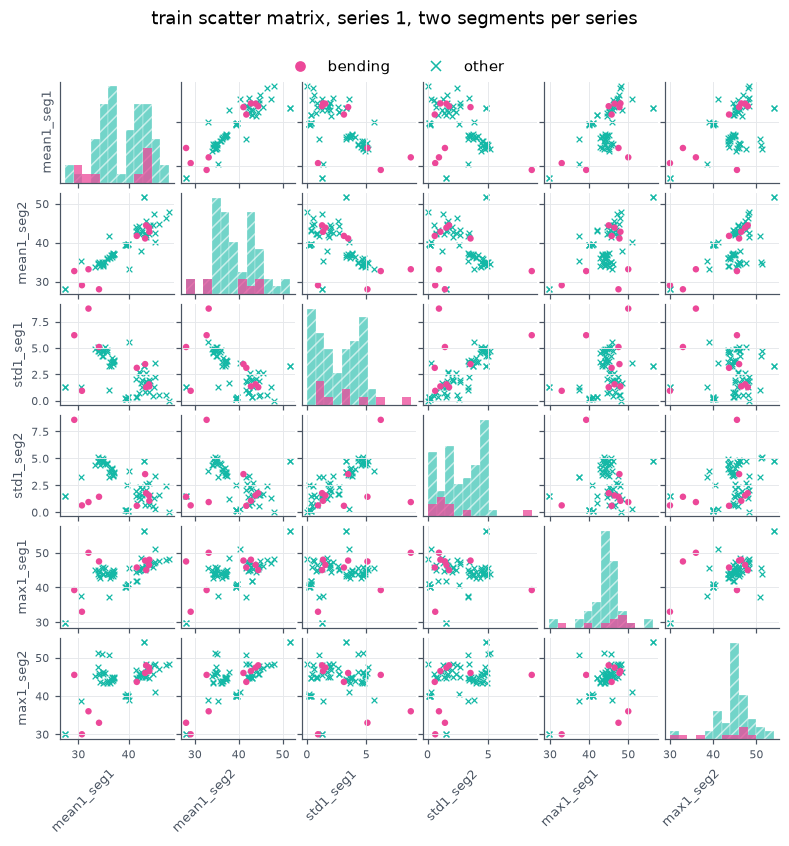

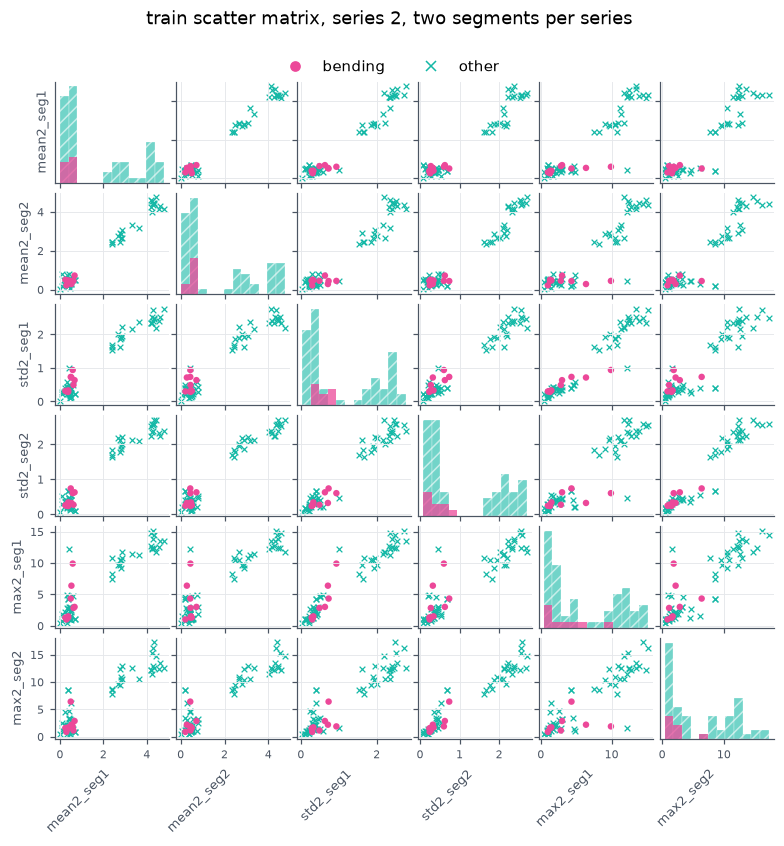

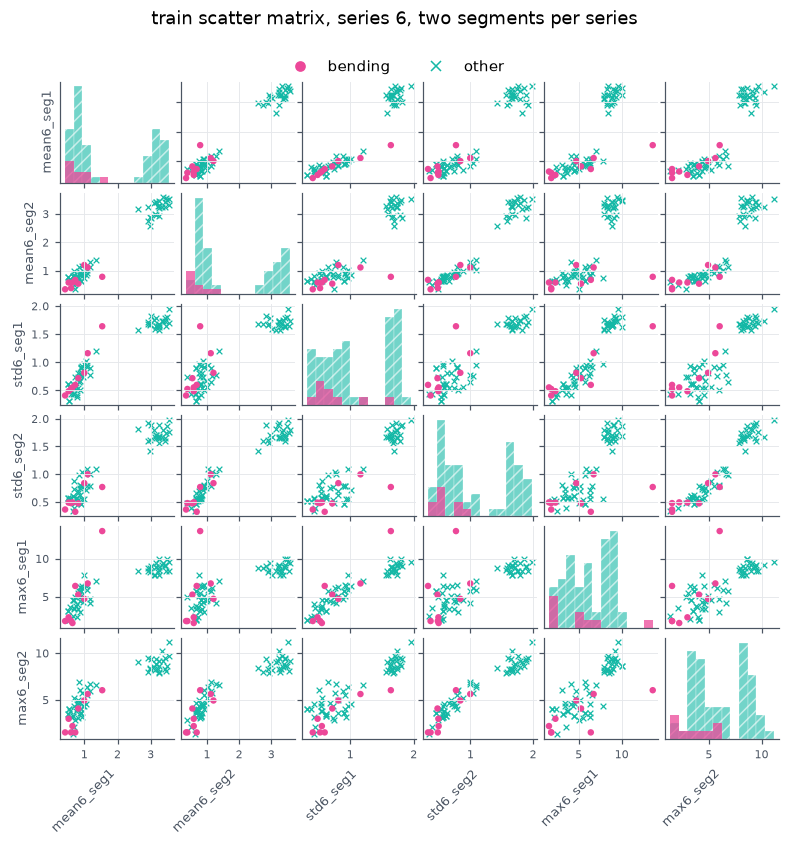

In [6]:
seg2_train = extract_features(train_instances, n_segments=2)
assert seg2_train.shape == (69, 2 + 42 * 2)
assert list(seg2_train["instance"]) == [i["id"] for i in train_instances]

# one larger figure per series instead of three cramped side-by-side matrices
for s in (1, 2, 6):
    cols = [f"{t}{s}_seg{g}" for t in SELECTED_TYPES for g in (1, 2)]
    fig = plt.figure(figsize=(7.6, 7.2))
    outer = GridSpec(1, 1, figure=fig, top=0.90, bottom=0.07, left=0.1, right=0.96)
    plot_scatter_matrix(fig, outer[0], cols, seg2_train, y_binary, "", rot=45)
    fig.suptitle(f"train scatter matrix, series {s}, two segments per series", y=0.99)
    fig.legend(handles=legend_handles, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 0.945))
    plt.show()

**2(a)ii answer.** No: the two-segment matrices do not show a considerable
difference from the unsegmented ones in 2(a)i. The classes occupy the same
regions before and after segmentation: bending (pink circles)
spans a broad std1 range reaching approximately 8 while most other
activities concentrate below about 5.5, a few bending points sit at the low
end of max1 below the other activities' cluster, and bending sits at low
values of the series 2 and 6 statistics; the other activities (teal crosses)
fill the same clusters in both versions. Segmenting doubles the number of panels
but produces no region in which the pink points separate from the teal mass
that the unsegmented panels do not already show. The model selection in
2(a)iii, run after these plots, agrees with this visual read: l = 1 (no
segmentation) attains the best CV accuracy of the whole (l, p) grid, and no
l > 1 improves on it.

## 2(a)iii binary classification with segmented features: pick l and p

For every l in 1..20 the feature pool holds all 7 time statistics of all 6
series in each of the l segments: 7 x 6 x l = 42l features. On top of that
pool a binary (bending vs other) logistic regression is fit with **backward
feature selection via RFE**, and the pair (l, p) with p = number of retained
features is chosen by stratified 5-fold CV.

- **Unregularized fit.** The logistic regression is unregularized; with the
  installed scikit-learn 1.9 that is `C = np.inf` (the handout's footnote 3
  suggests C approaching infinity; `penalty=None` is deprecated since 1.8
  and would emit warnings). `max_iter` is capped at 100, as footnote 5
  requires, because these fits are run on (nearly) separable data; the
  resulting (intentional) `ConvergenceWarning` is the one warning this
  notebook filters, scoped to exactly these fits.
- **Why RFE.** P-value pruning cannot run on the full pool: with 42l
  features and only about 55 rows per training fold the classical
  fit-then-drop-worst-p-value loop is not even estimable. The handout allows
  backward selection, so RFE is the selection method.
- **The p grid: exhaustive over the valid integer range.** For each l the
  search evaluates **every integer p = 1, ..., p_cap[l]**, where p_cap[l] is
  the largest valid p for that l: a candidate is valid only if every
  training fold retains at least p nonconstant features after the variance
  filter, and p also stays below the training-fold row count (about 55;
  minus one for the intercept) so the unregularized fit remains estimable.
  The per-l caps are printed with the search, and invalid (l, p) cells are
  left blank in the table and heatmap. A coarse subsample of the p axis
  could skip valid feature counts entirely (and would make the reported
  optimum depend on which p values happen to be tested), so no integer in
  the valid range is left untested.
- **Instability caveat.** The logistic fits behind RFE are intentionally
  truncated under separation (footnote 5), and elimination rankings from
  such fits can be unstable; fold averaging and the fixed tie-break rule
  absorb part of that, but accuracy differences of a few tenths of a percent
  are not treated as meaningful.
- **Efficiency.** One RFE run with `step = 1` down to a single feature yields
  the complete elimination order, and the top-p features of that order are
  exactly the set `RFE(p)` keeps; the search therefore scores every p from
  one ranking per (l, fold) instead of refitting RFE per p. The equivalence
  is asserted once below on (l = 5, first fold, p = 5).
- **Leakage control.** Everything data-dependent (variance filtering,
  standardization, feature ranking) lives inside `Pipeline`/fold logic that
  is fit on the training fold only and applied to the held-out fold. The
  right way: select and fit inside each training fold, score on the fold left
  out. The wrong way: rank features on all 69 rows before CV, or pick l and p
  by test-set results. The wrong way inflates accuracy because information
  from the evaluation rows (all 69 rows, or the test set) leaks into the
  model, so the CV or test score stops estimating error on unseen data.
- **Tie-break rule, stated up front:** highest mean CV accuracy; ties are
  broken toward the smallest l, then the smallest p.
- **Reference point.** The majority-class baseline is 60/69 = 0.870, so raw
  accuracy is a weak signal with only 9 bending instances in training; the
  best pair is therefore also scored with balanced accuracy and out-of-fold
  AUC.


In [7]:
# unregularized logistic regression, scikit-learn 1.9 spelling of penalty=None
def make_lr(max_iter=100):
    return LogisticRegression(C=np.inf, max_iter=max_iter)


MAX_L = 20

X_by_l = {l: extract_features(train_instances, n_segments=l).drop(columns=["instance", "activity"])
          for l in range(1, MAX_L + 1)}
assert all(X.shape == (69, 42 * l) for l, X in X_by_l.items())
splits_by_l = {l: list(CV5.split(X, y_binary)) for l, X in X_by_l.items()}

# largest valid p for every l: each training fold must keep at least p
# nonconstant features after variance filtering, and p must stay below the
# training-fold row count (minus the intercept) for the fit to remain estimable
p_cap = {}
for l, X in X_by_l.items():
    min_keep = min(int(VarianceThreshold().fit(X.iloc[tr_idx]).get_support().sum())
                   for tr_idx, _ in splits_by_l[l])
    min_rows = min(len(tr_idx) for tr_idx, _ in splits_by_l[l])
    p_cap[l] = min(min_keep, min_rows - 1)
print("largest valid p per l (bounded by fold nonconstant features and fold size):")
print(pd.Series({f"l = {l}": p_cap[l] for l in sorted(p_cap)}).to_string())

# exhaustive p grid: for every l, every integer p = 1..p_cap[l] is scored, so
# no valid feature count is skipped by the search
P_GRID = {l: list(range(1, p_cap[l] + 1)) for l in sorted(p_cap)}
assert all(P_GRID[l] == list(range(1, p_cap[l] + 1)) for l in P_GRID)

# verify the rfe shortcut once: (l = 5, first cv fold, p = 5)
X5 = X_by_l[5]
tr_idx, _ = splits_by_l[5][0]
X5_tr = X5.iloc[tr_idx]
vt5 = VarianceThreshold().fit(X5_tr)          # training rows only
cols5 = X5.columns[vt5.get_support()]
X5_tr_v = pd.DataFrame(vt5.transform(X5_tr), columns=cols5, index=X5_tr.index)
rfe_one = RFE(Pipeline([("scaler", StandardScaler()), ("lr", make_lr())]),
              n_features_to_select=1, step=1,
              importance_getter=lambda est: est[-1].coef_).fit(X5_tr_v, y_binary[tr_idx])
rfe_five = RFE(Pipeline([("scaler", StandardScaler()), ("lr", make_lr())]),
               n_features_to_select=5, step=1,
               importance_getter=lambda est: est[-1].coef_).fit(X5_tr_v, y_binary[tr_idx])
assert set(np.argsort(rfe_one.ranking_)[:5]) == set(np.where(rfe_five.support_)[0])
print("rfe shortcut verified: top-5 of the full elimination order == rfe with p = 5")


def cv_binary_l(l, X, y):
    # mean cv accuracy for every integer p in 1..p_cap[l]; variance filtering,
    # standardizing, and ranking all happen inside each training fold
    scores = {p: [] for p in P_GRID[l]}
    # the notebook's single allowed warning filter: the unregularized fits are
    # capped at max_iter = 100 by design (footnote 5), so their lbfgs
    # convergence warnings are expected and intentionally silenced here only
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", category=ConvergenceWarning,
                                message=".*lbfgs failed to converge.*")
        for tr_idx, va_idx in splits_by_l[l]:
            X_tr, X_va = X.iloc[tr_idx], X.iloc[va_idx]
            y_tr, y_va = y[tr_idx], y[va_idx]
            vt = VarianceThreshold().fit(X_tr)  # some columns are constant (the
            keep = X.columns[vt.get_support()]  # min of the variance series is 0)
            X_tr_v = pd.DataFrame(vt.transform(X_tr), columns=keep, index=X_tr.index)
            X_va_v = X_va.iloc[:, vt.get_support()]
            pipe = Pipeline([("scaler", StandardScaler()), ("lr", make_lr())])
            rfe = RFE(pipe, n_features_to_select=1, step=1,
                      importance_getter=lambda est: est[-1].coef_).fit(X_tr_v, y_tr)
            order = np.argsort(rfe.ranking_)
            for p in scores:
                top = order[:p]
                pipe_p = Pipeline([("scaler", StandardScaler()), ("lr", make_lr())])
                pipe_p.fit(X_tr_v.iloc[:, top], y_tr)
                scores[p].append(accuracy_score(y_va, pipe_p.predict(X_va_v.iloc[:, top])))
    return {p: float(np.mean(v)) for p, v in scores.items()}


cv_table = pd.DataFrame(np.nan, index=range(1, MAX_L + 1),
                        columns=range(1, max(p_cap.values())), dtype=float)
for l, X in X_by_l.items():
    for p, acc in cv_binary_l(l, X, y_binary).items():
        cv_table.loc[l, p] = acc
cv_table.index.name = "l"
cv_table.columns.name = "p"

# tie-break: highest cv accuracy, then smallest l, then smallest p
valid_pairs = [(l, p) for l in cv_table.index for p in cv_table.columns
               if pd.notna(cv_table.loc[l, p])]
best_l, best_p = max(valid_pairs,
                     key=lambda lp: (cv_table.loc[lp[0], lp[1]], -lp[0], -lp[1]))
others = [cv_table.loc[l, p] for (l, p) in valid_pairs if (l, p) != (best_l, best_p)]
print(f"best (l, p) = ({best_l}, {best_p}) with cv accuracy {cv_table.loc[best_l, best_p]:.3f}; "
      f"best other valid cell: {max(others):.3f}")
boundary = best_p >= p_cap[best_l]
print(f"winner on the grid boundary (p = best possible p for l = {best_l}): {boundary}")
max_cells = [(l, int(p)) for (l, p) in valid_pairs
             if cv_table.loc[l, p] == cv_table.loc[best_l, best_p]]
print(f"{len(max_cells)} valid cells attain the maximum: {max_cells}")
# transposed so every tested p is a row: a 50-plus-column frame would be
# collapsed to a truncated pandas summary, hiding tested p values
cv_table.T.round(3)


largest valid p per l (bounded by fold nonconstant features and fold size):
l = 1     39
l = 2     54
l = 3     54
l = 4     54
l = 5     54
l = 6     54
l = 7     54
l = 8     54
l = 9     54
l = 10    54
l = 11    54
l = 12    54
l = 13    54
l = 14    54
l = 15    54
l = 16    54
l = 17    54
l = 18    54
l = 19    54
l = 20    54


rfe shortcut verified: top-5 of the full elimination order == rfe with p = 5


best (l, p) = (1, 16) with cv accuracy 0.986; best other valid cell: 0.986
winner on the grid boundary (p = best possible p for l = 1): False
18 valid cells attain the maximum: [(1, 16), (1, 17), (1, 20), (1, 21), (1, 22), (1, 23), (1, 24), (1, 25), (1, 26), (1, 27), (1, 28), (1, 29), (1, 30), (1, 31), (1, 32), (1, 33), (1, 34), (1, 35)]


l,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
p,,,,,,,,,,,,,,,,,,,,
1,0.913,0.913,0.942,0.929,0.957,0.943,0.886,0.913,0.929,0.913,0.943,0.957,0.927,0.929,0.899,0.900,0.943,0.943,0.957,0.943
2,0.927,0.900,0.913,0.899,0.942,0.929,0.929,0.971,0.856,0.929,0.913,0.957,0.929,0.885,0.957,0.886,0.943,0.943,0.971,0.957
3,0.929,0.929,0.899,0.913,0.927,0.929,0.913,0.943,0.900,0.957,0.943,0.914,0.929,0.957,0.898,0.899,0.943,0.957,0.971,0.956
4,0.971,0.943,0.929,0.927,0.957,0.943,0.942,0.900,0.913,0.957,0.943,0.929,0.929,0.943,0.913,0.899,0.957,0.957,0.971,0.971
5,0.957,0.957,0.914,0.942,0.942,0.957,0.942,0.900,0.913,0.957,0.957,0.929,0.914,0.943,0.929,0.913,0.971,0.957,0.943,0.971
6,0.957,0.971,0.943,0.942,0.927,0.943,0.942,0.914,0.929,0.957,0.957,0.929,0.914,0.929,0.929,0.914,0.957,0.943,0.943,0.971
7,0.957,0.942,0.927,0.942,0.927,0.957,0.956,0.900,0.929,0.957,0.957,0.914,0.885,0.943,0.929,0.929,0.971,0.957,0.957,0.971
8,0.957,0.942,0.927,0.942,0.927,0.957,0.957,0.914,0.913,0.971,0.957,0.914,0.899,0.914,0.929,0.943,0.971,0.957,0.957,0.971
9,0.957,0.956,0.943,0.957,0.927,0.943,0.942,0.929,0.913,0.957,0.957,0.929,0.914,0.913,0.929,0.943,0.943,0.957,0.957,0.971


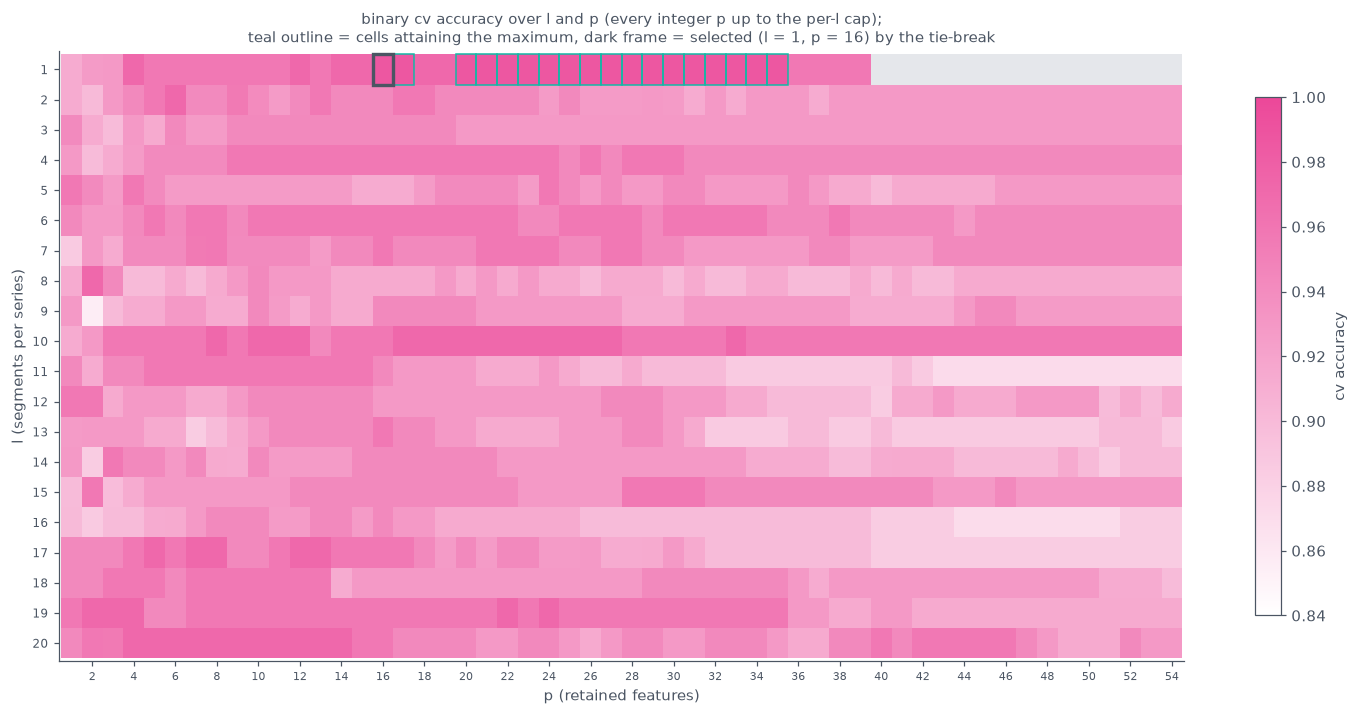

In [8]:
cmap_pink = LinearSegmentedColormap.from_list("hw4", ["#FFFFFF", PINK])
cmap_pink.set_bad("#E5E7EB")   # blank cells = (l, p) combinations that are not valid
vmin = float(np.floor(np.nanmin(cv_table.to_numpy(dtype=float)) / 0.02) * 0.02)
fig, ax = plt.subplots(figsize=(16.5, 7.2))
im = ax.imshow(cv_table.to_numpy(dtype=float), cmap=cmap_pink, aspect="auto",
               vmin=vmin, vmax=1.0)
# 54 columns stay legible with every second p labeled and no per-cell text;
# the complete numeric grid is the transposed table printed above
tick_ps = list(range(2, cv_table.shape[1] + 1, 2))
ax.set_xticks([p - 1 for p in tick_ps], tick_ps, fontsize=7)
ax.set_yticks(range(MAX_L), range(1, MAX_L + 1), fontsize=8)
ax.set_xlabel("p (retained features)")
ax.set_ylabel("l (segments per series)")
ax.set_title("binary cv accuracy over l and p (every integer p up to the per-l cap);\n"
             f"teal outline = cells attaining the maximum, dark frame = selected "
             f"(l = {best_l}, p = {best_p}) by the tie-break", fontsize=10)
for (l, p) in max_cells:
    ax.add_patch(Rectangle((p - 1.5, l - 1.5), 1, 1, fill=False,
                           edgecolor=TEAL, linewidth=1.0))
ax.add_patch(Rectangle((best_p - 1.5, best_l - 1.5), 1, 1, fill=False,
                       edgecolor=NEUTRAL, linewidth=2.2))
ax.grid(False)
ax.set_xlim(-0.6, cv_table.shape[1] - 0.4)
ax.set_ylim(MAX_L - 0.4, -0.6)
fig.colorbar(im, ax=ax, shrink=0.85, label="cv accuracy")
plt.show()


In [9]:
# out-of-fold scores of the winning (l, p): balanced accuracy and auc, because
# plain accuracy sits close to the 0.870 majority baseline with 9 positives
X_best = X_by_l[best_l]
oof_p = np.zeros(69)
oof_y = np.zeros(69, dtype=int)
fold_acc = []
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", category=ConvergenceWarning,
                            message=".*lbfgs failed to converge.*")
    for tr_idx, va_idx in CV5.split(X_best, y_binary):
        X_tr, X_va = X_best.iloc[tr_idx], X_best.iloc[va_idx]
        vt = VarianceThreshold().fit(X_tr)
        cols = X_best.columns[vt.get_support()]
        X_tr_v = pd.DataFrame(vt.transform(X_tr), columns=cols, index=X_tr.index)
        X_va_v = X_va.iloc[:, vt.get_support()]
        rfe = RFE(Pipeline([("scaler", StandardScaler()), ("lr", make_lr())]),
                  n_features_to_select=1, step=1,
                  importance_getter=lambda est: est[-1].coef_).fit(X_tr_v, y_binary[tr_idx])
        top = np.argsort(rfe.ranking_)[:best_p]
        pipe_p = Pipeline([("scaler", StandardScaler()), ("lr", make_lr())])
        pipe_p.fit(X_tr_v.iloc[:, top], y_binary[tr_idx])
        oof_p[va_idx] = pipe_p.predict_proba(X_va_v.iloc[:, top])[:, 1]
        oof_y[va_idx] = y_binary[va_idx]
        fold_acc.append(accuracy_score(y_binary[va_idx], oof_p[va_idx] > 0.5))

fpr_cv, tpr_cv, _ = roc_curve(oof_y, oof_p)
cv_auc = auc(fpr_cv, tpr_cv)
cv_acc = float(np.mean(fold_acc))
cv_bal_acc = balanced_accuracy_score(oof_y, oof_p > 0.5)
baseline = float((y_binary == 0).mean())
print(f"majority-class baseline (always other): {baseline:.3f}  (= 60/69)")
print(f"cv accuracy  at best (l, p):            {cv_acc:.3f}")
print(f"cv balanced accuracy at best (l, p):    {cv_bal_acc:.3f}")
print(f"cv auc (out-of-fold probabilities):     {cv_auc:.3f}")

# retained features of the final model: same protocol on all 69 training rows
vt_final = VarianceThreshold().fit(X_best)
cols_final = X_best.columns[vt_final.get_support()]
X_final_v = pd.DataFrame(vt_final.transform(X_best), columns=cols_final, index=X_best.index)
ranking_final = RFE(Pipeline([("scaler", StandardScaler()), ("lr", make_lr())]),
                    n_features_to_select=1, step=1,
                    importance_getter=lambda est: est[-1].coef_).fit(X_final_v, y_binary).ranking_
retained = list(cols_final[np.argsort(ranking_final)[:best_p]])
print(f"\nretained features of the final model (l = {best_l}, p = {best_p}):")
for name in retained:
    print(f"  {name}")

majority-class baseline (always other): 0.870  (= 60/69)
cv accuracy  at best (l, p):            0.986
cv balanced accuracy at best (l, p):    0.992
cv auc (out-of-fold probabilities):     0.996

retained features of the final model (l = 1, p = 16):
  min5
  max5
  q3_1
  q1_6
  max4
  q1_4
  mean5
  q3_3
  min1
  max2
  max1
  std6
  mean1
  q1_5
  median4
  max3


**2(a)iii answer.** The exhaustive search over every valid integer p selects
**l = 1 and p = 16**, with mean CV accuracy **0.986** against the
majority-class baseline of 60/69 = **0.870**; the same pair reaches balanced
accuracy **0.992** and out-of-fold AUC **0.996**. Because the grid now
contains every valid integer p, the location of the maximum is exact: at
l = 1 it is attained by **p = 16, p = 17, and p = 20 through p = 35** (18
cells; the complete list is printed with the search). That set is **not** one
uninterrupted plateau: p = 18 and p = 19 fall back to 0.971, so the
attaining cells form two runs separated by a dip, and the maximum is an
interior optimum (the valid cap for l = 1 is p = 39, and the printed
boundary check reports that the winner is not on it). The declared tie-break
(highest accuracy, then smallest l, then smallest p) therefore selects
**p = 16, the smallest p attaining the maximum**. Segmentation still does
not help: no l >= 2 configuration exceeds **0.971**, consistent with the
absence of a visible gain in 2(a)ii. Two caveats stated in the method
section bear repeating. First, the RFE rankings come from intentionally
truncated logistic fits on nearly separable data, so they can be unstable
under separation; the exact retained set of 16 features (listed above,
spanning all six series) should not be over-interpreted. Second, the table
moves in one-error steps: the drop from 0.986 to 0.971 equals one additional
validation error in one 14-row fold spread over the 5 folds, so
neighboring-p differences of that size reflect fold granularity and ranking
instability rather than a substantive accuracy change.


## 2(a)iv final model on the training set

The winning protocol from 2(a)iii is refit on all 69 training rows: the report
below shows its training confusion matrix, the training ROC with AUC computed
from decision scores, and the coefficients beta_i with p-values from
`statsmodels`. The features are standardized (scaler fit on the training
rows) before fitting, so every beta is on the **standardized scale**: a
one-standard-deviation change in the raw feature.

train accuracy: 1.000
train auc (decision scores): 1.000


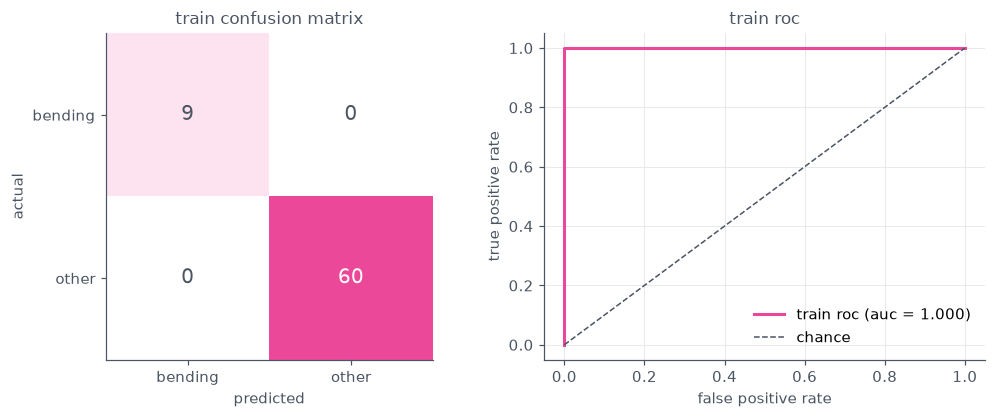

,pred bending,pred other
actual bending,9,0
actual other,0,60


In [10]:
final_pipe = Pipeline([("scaler", StandardScaler()), ("lr", make_lr())])
final_pipe.fit(X_final_v[retained], y_binary)

train_pred = final_pipe.predict(X_final_v[retained])
train_score = final_pipe.decision_function(X_final_v[retained])
train_proba = 1 / (1 + np.exp(-train_score))
fpr_tr, tpr_tr, _ = roc_curve(y_binary, train_score)
train_auc = auc(fpr_tr, tpr_tr)
print(f"train accuracy: {accuracy_score(y_binary, train_pred):.3f}")
print(f"train auc (decision scores): {train_auc:.3f}")


def confusion_df(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[1, 0])
    return pd.DataFrame(cm, index=["actual bending", "actual other"],
                        columns=["pred bending", "pred other"])


fig, (ax_cm, ax_roc) = plt.subplots(1, 2, figsize=(9.5, 3.9))
cm_arr = confusion_matrix(y_binary, train_pred, labels=[1, 0])
ax_cm.imshow(cm_arr, cmap=cmap_pink, vmin=0, vmax=cm_arr.max())
for r in range(2):
    for c in range(2):
        ax_cm.text(c, r, cm_arr[r, c], ha="center", va="center", fontsize=13,
                   color="white" if cm_arr[r, c] > cm_arr.max() / 2 else NEUTRAL)
ax_cm.set_xticks([0, 1], ["bending", "other"])
ax_cm.set_yticks([0, 1], ["bending", "other"])
ax_cm.set_xlabel("predicted")
ax_cm.set_ylabel("actual")
ax_cm.set_title("train confusion matrix")
ax_cm.grid(False)
ax_roc.plot(fpr_tr, tpr_tr, color=PINK, linewidth=2,
            label=f"train roc (auc = {train_auc:.3f})")
ax_roc.plot([0, 1], [0, 1], color=NEUTRAL, linewidth=1, linestyle="--", label="chance")
ax_roc.set_xlabel("false positive rate")
ax_roc.set_ylabel("true positive rate")
ax_roc.set_title("train roc")
ax_roc.legend(loc="lower right")
fig.tight_layout()
plt.show()

confusion_df(y_binary, train_pred)

In [11]:
# coefficients and p-values: statsmodels logit on the same standardized
# features (statsmodels has no penalty option, this is a pure classical fit)
X_sm = pd.DataFrame(final_pipe[0].transform(X_final_v[retained]), columns=retained)
logit_model = sm.Logit(y_binary, sm.add_constant(X_sm))
with warnings.catch_warnings():
    # perfect separation is guaranteed here (the classes split cleanly in
    # 2(a)iii), so statsmodels necessarily reports PerfectSeparationWarning,
    # its own ConvergenceWarning, and overflow RuntimeWarnings; each of them
    # is an expected symptom that the fallback below addresses explicitly,
    # and they are silenced inside this block only
    warnings.filterwarnings("ignore", category=PerfectSeparationWarning)
    warnings.filterwarnings("ignore", category=SmConvergenceWarning)
    warnings.filterwarnings("ignore", category=HessianInversionWarning)
    warnings.filterwarnings("ignore", category=RuntimeWarning)
    sm_res = logit_model.fit(disp=0, maxiter=200)

sm_converged = bool(sm_res.mle_retvals.get("converged", False))
params = np.asarray(sm_res.params)

# fallback: wald p-values from the observed information (-hessian) at the
# fitted parameters, inverted with a pseudo-inverse because the hessian is
# near-singular under separation
info = -logit_model.hessian(params)
cov_pinv = np.linalg.pinv(info)
se_pinv = np.sqrt(np.clip(np.diag(cov_pinv), 0, None))
p_pinv = 2 * norm.sf(np.abs(params / se_pinv))

coef_table = pd.DataFrame({
    "term": ["intercept"] + retained,
    "beta (standardized)": params,
    "se (statsmodels)": np.asarray(sm_res.bse),
    "p (statsmodels)": np.asarray(sm_res.pvalues),
    "se (pinv)": se_pinv,
    "p (pinv)": p_pinv,
})
print(f"logit converged: {sm_converged}; max |beta| = {np.abs(params).max():.1f}; "
      f"max p (both methods) = {max(sm_res.pvalues.max(), p_pinv.max()):.4f}")
coef_table.round(4)

logit converged: False; max |beta| = 32.1; max p (both methods) = 1.0000


,term,beta (standardized),se (statsmodels),p (statsmodels),se (pinv),p (pinv)
0,intercept,-32.0939,6.931039e+05,1.0,6.931039e+05,1.0
1,min5,22.2961,4.577761e+06,1.0,4.577761e+06,1.0
2,max5,6.7913,1.987013e+06,1.0,1.987013e+06,1.0
3,q3_1,-22.5655,2.644584e+06,1.0,2.644584e+06,1.0
4,q1_6,-0.7103,4.499886e+06,1.0,4.499886e+06,1.0
5,max4,10.6794,8.203822e+05,1.0,8.203822e+05,1.0
6,q1_4,-15.5363,3.469201e+06,1.0,3.469201e+06,1.0
7,mean5,-14.8596,1.417974e+07,1.0,1.417974e+07,1.0
8,q3_3,-5.0930,1.875014e+06,1.0,1.875014e+06,1.0
9,min1,-7.6177,4.899980e+05,1.0,4.899980e+05,1.0


**2(a)iv answer.** On the 69 training rows the final model (l = 1, p = 16)
classifies every instance correctly (train accuracy 1.000, train AUC 1.000
from decision scores). The betas in the table are on the **standardized
scale** (each feature is scaled by its training mean and standard deviation
before the fit). Because the classes are perfectly separated, the
statsmodels logit does **not converge** (`mle_retvals` reports convergence
failure and perfect separation), so its p-values, and the fallback Wald
p-values computed from the pseudo-inverse of the observed information, are
**unreliable and should be read as such**: both routes return standard
errors between roughly 7e5 and 1.4e7 and p-values of essentially 1.0 for
every coefficient, the textbook signature of an unidentified likelihood. The
coefficients themselves are only directionally meaningful: the largest
standardized betas are q3_1 (-22.6), min5 (+22.3), q1_4 (-15.5), and mean5
(-14.9), with the intercept at -32.1.

## 2(a)v test evaluation

The 19 test instances are segmented with the identical l chosen in 2(a)iii and
the identical feature definitions, passed through the variance filter and
scaler **fit on training data only**, and scored by the final model from
2(a)iv.

test accuracy: 1.000 (19/19)
test auc: 1.000
cv accuracy of the same (l, p): 0.986; the test set holds only 4 positives


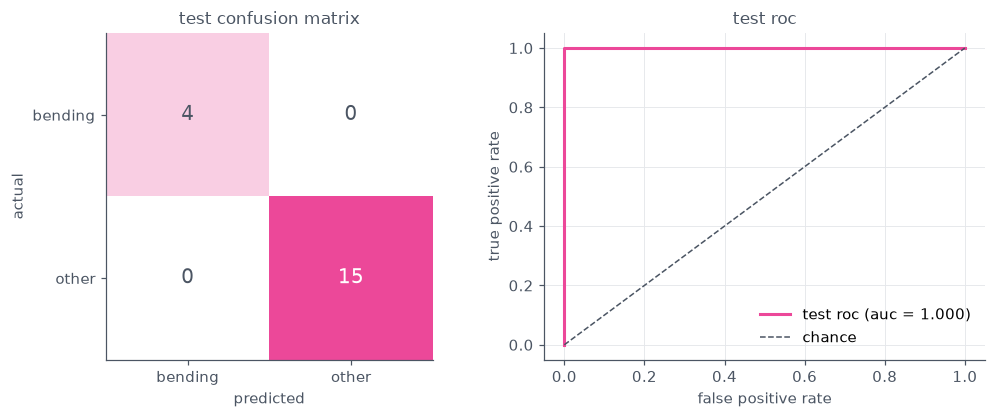

,pred bending,pred other
actual bending,4,0
actual other,0,15


In [12]:
test_instances = [i for i in instances if i["split"] == "test"]
test_feats = extract_features(test_instances, n_segments=best_l).drop(
    columns=["instance", "activity"])
assert list(test_feats.columns) == list(X_by_l[best_l].columns)  # identical features
y_test = np.array([i["activity"] in BENDING for i in test_instances])
assert y_test.sum() == 4 and len(y_test) == 19

X_test_v = pd.DataFrame(vt_final.transform(test_feats), columns=cols_final,
                        index=test_feats.index)
test_pred = final_pipe.predict(X_test_v[retained])
test_score = final_pipe.decision_function(X_test_v[retained])
fpr_te, tpr_te, _ = roc_curve(y_test, test_score)
test_auc = auc(fpr_te, tpr_te)
test_acc = accuracy_score(y_test, test_pred)
print(f"test accuracy: {test_acc:.3f} ({(y_test == test_pred).sum()}/19)")
print(f"test auc: {test_auc:.3f}")
print(f"cv accuracy of the same (l, p): {cv_acc:.3f}; the test set holds only 4 positives")

fig, (ax_cm, ax_roc) = plt.subplots(1, 2, figsize=(9.5, 3.9))
cm_arr = confusion_matrix(y_test, test_pred, labels=[1, 0])
ax_cm.imshow(cm_arr, cmap=cmap_pink, vmin=0, vmax=cm_arr.max())
for r in range(2):
    for c in range(2):
        ax_cm.text(c, r, cm_arr[r, c], ha="center", va="center", fontsize=13,
                   color="white" if cm_arr[r, c] > cm_arr.max() / 2 else NEUTRAL)
ax_cm.set_xticks([0, 1], ["bending", "other"])
ax_cm.set_yticks([0, 1], ["bending", "other"])
ax_cm.set_xlabel("predicted")
ax_cm.set_ylabel("actual")
ax_cm.set_title("test confusion matrix")
ax_cm.grid(False)
ax_roc.plot(fpr_te, tpr_te, color=PINK, linewidth=2,
            label=f"test roc (auc = {test_auc:.3f})")
ax_roc.plot([0, 1], [0, 1], color=NEUTRAL, linewidth=1, linestyle="--", label="chance")
ax_roc.set_xlabel("false positive rate")
ax_roc.set_ylabel("true positive rate")
ax_roc.set_title("test roc")
ax_roc.legend(loc="lower right")
fig.tight_layout()
plt.show()

confusion_df(y_test, test_pred)

**2(a)v answer.** The final model classifies all 19 test instances
correctly: test accuracy **1.000** with confusion matrix 4/4 bending and
15/15 other, and test AUC **1.000**. That is better than the cross-validated
accuracy of the same (l, p), 0.986, which is plausible but should be read
with care: the test set holds only 4 positives, so one misclassified bending
instance would cost 0.053 accuracy, and a perfect score on 19 rows is weak
evidence by itself.

## 2(a)vi are the classes separable? instability evidence

Evidence collected from the fitted model: training accuracy and AUC, the
optimizer's stopping behavior, coefficient magnitudes, standard errors,
p-values, and how extreme the predicted probabilities are.

In [13]:
print(f"1. train accuracy = {accuracy_score(y_binary, train_pred):.3f}, "
      f"train auc = {train_auc:.3f} (perfect classification of the training rows)")
print(f"2. the sklearn lbfgs fit terminated on its own numerical criterion after "
      f"n_iter_ = {final_pipe[-1].n_iter_[0]} of at most {final_pipe[-1].max_iter} "
      f"iterations and emitted no warning; stopping before max_iter normally "
      f"indicates that the optimizer converged numerically")
print(f"3. the statsmodels fit, on the same standardized design, converged: {sm_converged} "
      f"(it reports perfect separation and fails to converge)")
print(f"4. max |beta| (standardized scale) = {np.abs(params).max():.1f}; "
      f"median |beta| = {np.median(np.abs(params)):.1f}")
print(f"5. max std err: statsmodels = {np.nanmax(sm_res.bse):.3g}, "
      f"pseudo-inverse = {se_pinv.max():.3g} (both blow up under separation)")
print(f"6. p-values: max (statsmodels) = {np.nanmax(sm_res.pvalues):.4f}, "
      f"max (pinv) = {p_pinv.max():.4f}; nothing is significant, the classic separation signature")
print(f"7. train predicted probabilities in [{train_proba.min():.4f}, {train_proba.max():.4f}]; "
      f"{np.mean((train_proba < 0.02) | (train_proba > 0.98)) * 100:.0f}% of them lie within 0.02 of 0 or 1")

1. train accuracy = 1.000, train auc = 1.000 (perfect classification of the training rows)
2. the sklearn lbfgs fit terminated on its own numerical criterion after n_iter_ = 13 of at most 100 iterations and emitted no warning; stopping before max_iter normally indicates that the optimizer converged numerically
3. the statsmodels fit, on the same standardized design, converged: False (it reports perfect separation and fails to converge)
4. max |beta| (standardized scale) = 32.1; median |beta| = 7.7
5. max std err: statsmodels = 1.42e+07, pseudo-inverse = 1.42e+07 (both blow up under separation)
6. p-values: max (statsmodels) = 1.0000, max (pinv) = 1.0000; nothing is significant, the classic separation signature
7. train predicted probabilities in [0.0000, 1.0000]; 100% of them lie within 0.02 of 0 or 1


**2(a)vi answer.** Yes, the classes are separated enough to make the
unregularized estimates unstable, although the sklearn optimizer itself
stops cleanly. The printed evidence, line by line: (1) training accuracy and
AUC are both exactly 1.000; (2) the sklearn lbfgs fit terminates on its own
numerical criterion after 13 of at most 100 iterations and emits no warning,
and stopping before max_iter normally indicates numerical convergence, so
no optimizer failure is claimed for it; (3) the statsmodels fit of the same
standardized design, which has no comparable early-stopping behavior,
reports perfect separation and fails to converge; (4) standardized
coefficients reach |beta| = 32.1 (median 7.7), far outside the range where
individual feature effects are interpretable; (5) standard errors blow up to
about 1.4e7 in both the statsmodels and the pseudo-inverse calculation;
(6) every p-value is 1.0, so no coefficient is identified; (7) all 69
predicted training probabilities lie within 0.02 of 0 or 1, the
extreme-probability pattern of a separating hyperplane. Taken together, the
perfect training classification, the extreme probabilities, the statsmodels
nonconvergence and perfect-separation report, the very large coefficients,
and the exploding standard errors show that the classes are (nearly) fully
separable: predictions remain stable only while separation persists, while
the coefficient values, their standard errors, and the p-values are not
identifiable.

## 2(a)vii case-control sampling for the imbalanced classes

Training holds 9 bending vs 60 other instances. The case-control remedy keeps
**all 9 cases** and samples **9 controls (1:1 ratio, seed 42)**, refits the
same winning (l, p) model from 2(a)iii on the sample, and then corrects the
intercept back to the population prevalence:

b0_adj = b0 + log(pi / (1 - pi)) - log(pi_s / (1 - pi_s))

with pi = 9/69 the training prevalence and pi_s = 9/18 the case fraction in
the sample. The correction moves the decision threshold only; it shifts every
score by the same constant, so the ROC curve and AUC are unchanged by it.

case-control sample: 9 bending + 9 other (ratio 1:1)
b0 = 2.023; b0_adj = 0.126 (pi = 0.130, pi_s = 0.500)
auc before vs after intercept correction (train): 1.0000 vs 1.0000
train uncorrected accuracy 0.986  (TP 9, FN 0; FP 1, TN 59)
train corrected   accuracy 1.000  (TP 9, FN 0; FP 0, TN 60)
test  uncorrected accuracy 1.000  (TP 4, FN 0; FP 0, TN 15)
test  corrected   accuracy 1.000  (TP 4, FN 0; FP 0, TN 15)
adjusted model: train accuracy 1.000, train auc 1.000
adjusted model: test accuracy  1.000, test auc  1.000
original full-training model (2(a)iv/v): train accuracy 1.000, train auc 1.000; test accuracy 1.000, test auc 1.000


sensitivity over 20 resamples: train accuracy 0.957-1.000, test accuracy 1.000-1.000


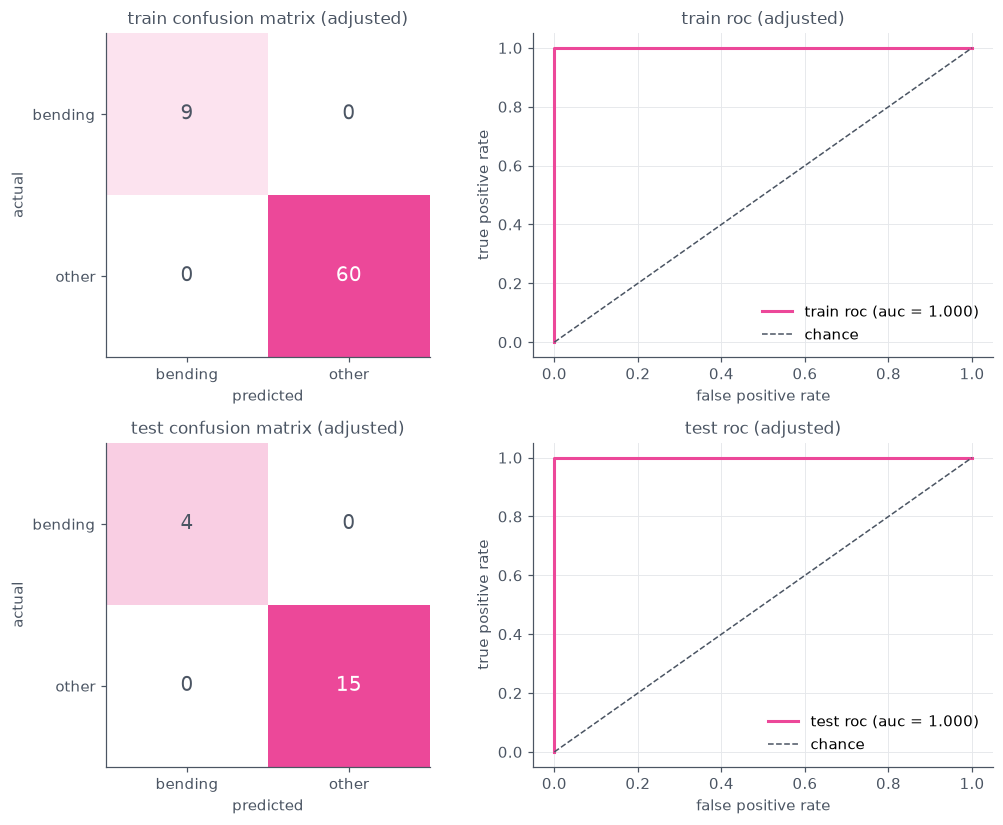

,model,train accuracy,train auc,test accuracy,test auc
0,original full-training model (2(a)iv/v),1.000,1.0,1.0,1.0
1,"case-control, uncorrected intercept",0.986,1.0,1.0,1.0
2,"case-control, corrected intercept",1.000,1.0,1.0,1.0


In [14]:
rng = np.random.default_rng(SEED)
case_idx = np.where(y_binary)[0]
control_idx = np.where(~y_binary)[0]
cc_control = rng.choice(control_idx, size=9, replace=False)
cc_idx = np.sort(np.concatenate([case_idx, cc_control]))
X_cc = X_final_v.iloc[cc_idx][retained]
y_cc = y_binary[cc_idx]
assert y_cc.sum() == 9 and (1 - y_cc).sum() == 9
print(f"case-control sample: {y_cc.sum()} bending + {(1 - y_cc).sum()} other (ratio 1:1)")

cc_pipe = Pipeline([("scaler", StandardScaler()), ("lr", make_lr())]).fit(X_cc, y_cc)
cc_scaler, cc_lr = cc_pipe[0], cc_pipe[-1]
pi = 9 / 69            # training prevalence
pi_s = 9 / 18          # case fraction in the sample
b0 = float(cc_lr.intercept_[0])
b0_adj = b0 + np.log(pi / (1 - pi)) - np.log(pi_s / (1 - pi_s))
print(f"b0 = {b0:.3f}; b0_adj = {b0_adj:.3f} "
      f"(pi = {pi:.3f}, pi_s = {pi_s:.3f})")


def cc_score(X):
    return cc_scaler.transform(X) @ cc_lr.coef_[0] + b0_adj


# the same scores with the uncorrected intercept differ only by the constant
# log(pi_s / (1 - pi_s)) - log(pi / (1 - pi)), so the auc is identical; show
# that on the training scores
score_raw = cc_scaler.transform(X_final_v[retained]) @ cc_lr.coef_[0] + b0
fpr_a, tpr_a, _ = roc_curve(y_binary, cc_score(X_final_v[retained]))
fpr_b, tpr_b, _ = roc_curve(y_binary, score_raw)
print(f"auc before vs after intercept correction (train): "
      f"{auc(fpr_b, tpr_b):.4f} vs {auc(fpr_a, tpr_a):.4f}")

# cc_score returns log-odds (decision scores), so the corrected rule is
# "positive when the corrected log-odds > 0", equivalent to a corrected
# probability > 0.5
cc_train_pred = (cc_score(X_final_v[retained]) > 0).astype(int)
cc_test_pred = (cc_score(X_test_v[retained]) > 0).astype(int)

# Uncorrected case-control predictions: same fitted model, but with the
# sampled-data intercept b0. Logistic decision scores use zero as the
# classification threshold.
raw_train_pred = (score_raw > 0).astype(int)
score_raw_test = (
    cc_scaler.transform(X_test_v[retained]) @ cc_lr.coef_[0] + b0
)
raw_test_pred = (score_raw_test > 0).astype(int)

for split, y_true, pred_raw, pred_corrected in [
    ("train", y_binary, raw_train_pred, cc_train_pred),
    ("test", y_test, raw_test_pred, cc_test_pred),
]:
    for model_name, pred in [
        ("uncorrected", pred_raw),
        ("corrected", pred_corrected),
    ]:
        tn, fp, fn, tp = confusion_matrix(
            y_true, pred, labels=[0, 1]
        ).ravel()
        print(
            f"{split:5s} {model_name:11s} "
            f"accuracy {accuracy_score(y_true, pred):.3f}  "
            f"(TP {tp}, FN {fn}; FP {fp}, TN {tn})"
        )

raw_train_auc = auc(*roc_curve(y_binary, score_raw)[:2])
raw_test_auc = auc(*roc_curve(y_test, score_raw_test)[:2])
cc_train_auc = auc(*roc_curve(y_binary, cc_score(X_final_v[retained]))[:2])
cc_test_auc = auc(*roc_curve(y_test, cc_score(X_test_v[retained]))[:2])
print(f"adjusted model: train accuracy {accuracy_score(y_binary, cc_train_pred):.3f}, "
      f"train auc {cc_train_auc:.3f}")
print(f"adjusted model: test accuracy  {accuracy_score(y_test, cc_test_pred):.3f}, "
      f"test auc  {cc_test_auc:.3f}")
print(f"original full-training model (2(a)iv/v): train accuracy "
      f"{accuracy_score(y_binary, train_pred):.3f}, train auc {train_auc:.3f}; "
      f"test accuracy {test_acc:.3f}, test auc {test_auc:.3f}")

# sensitivity check (not required): repeat the case-control sampling 20 times
# with different seeds and confirm the conclusions do not hinge on one sample;
# since pi_s = 0.5, the correction term on the intercept is log(pi / (1 - pi))
rep_train, rep_test = [], []
for rep in range(20):
    rng_rep = np.random.default_rng(SEED + 1 + rep)
    ctrl_rep = rng_rep.choice(control_idx, size=9, replace=False)
    idx_rep = np.sort(np.concatenate([case_idx, ctrl_rep]))
    pipe_rep = Pipeline([("scaler", StandardScaler()), ("lr", make_lr())]).fit(
        X_final_v.iloc[idx_rep][retained], y_binary[idx_rep])
    b0_rep = float(pipe_rep[-1].intercept_[0]) + np.log(pi / (1 - pi))

    def rep_score(X, _p=pipe_rep, _b0=b0_rep):
        return _p[0].transform(X) @ _p[-1].coef_[0] + _b0

    rep_train.append(accuracy_score(y_binary, rep_score(X_final_v[retained]) > 0))
    rep_test.append(accuracy_score(y_test, rep_score(X_test_v[retained]) > 0))
print(f"sensitivity over 20 resamples: train accuracy "
      f"{min(rep_train):.3f}-{max(rep_train):.3f}, "
      f"test accuracy {min(rep_test):.3f}-{max(rep_test):.3f}")

fig, axes = plt.subplots(2, 2, figsize=(9.5, 7.6))
for row, (y_true, y_hat, score, split) in enumerate([
        (y_binary, cc_train_pred, cc_score(X_final_v[retained]), "train"),
        (y_test, cc_test_pred, cc_score(X_test_v[retained]), "test")]):
    cm_arr = confusion_matrix(y_true, y_hat, labels=[1, 0])
    ax = axes[row, 0]
    ax.imshow(cm_arr, cmap=cmap_pink, vmin=0, vmax=cm_arr.max())
    for r in range(2):
        for c in range(2):
            ax.text(c, r, cm_arr[r, c], ha="center", va="center", fontsize=13,
                    color="white" if cm_arr[r, c] > cm_arr.max() / 2 else NEUTRAL)
    ax.set_xticks([0, 1], ["bending", "other"])
    ax.set_yticks([0, 1], ["bending", "other"])
    ax.set_xlabel("predicted")
    ax.set_ylabel("actual")
    ax.set_title(f"{split} confusion matrix (adjusted)")
    ax.grid(False)
    fpr, tpr, _ = roc_curve(y_true, score)
    ax = axes[row, 1]
    ax.plot(fpr, tpr, color=PINK, linewidth=2,
            label=f"{split} roc (auc = {auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], color=NEUTRAL, linewidth=1, linestyle="--", label="chance")
    ax.set_xlabel("false positive rate")
    ax.set_ylabel("true positive rate")
    ax.set_title(f"{split} roc (adjusted)")
    ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

pd.DataFrame({
    "model": ["original full-training model (2(a)iv/v)",
              "case-control, uncorrected intercept",
              "case-control, corrected intercept"],
    "train accuracy": [accuracy_score(y_binary, train_pred),
                       accuracy_score(y_binary, raw_train_pred),
                       accuracy_score(y_binary, cc_train_pred)],
    "train auc": [train_auc, raw_train_auc, cc_train_auc],
    "test accuracy": [test_acc,
                      accuracy_score(y_test, raw_test_pred),
                      accuracy_score(y_test, cc_test_pred)],
    "test auc": [test_auc, raw_test_auc, cc_test_auc],
}).round(3)

**2(a)vii answer.** The 1:1 case-control refit (9 bending, 9 sampled
controls, seed 42) moves the intercept from b0 = 2.023 to the corrected
b0_adj = 0.126: the signed prior-odds correction is
log(pi / (1 - pi)) - log(pi_s / (1 - pi_s)) = log(0.15) - log(1) = **-1.897**,
so b0_adj = 2.023 - 1.897 = 0.126, mapping the sample's 50/50 odds back to
the 9/69 training prevalence. `cc_score` returns **log-odds** (logistic
decision scores), so predictions compare the corrected score with **zero**,
which is exactly equivalent to comparing the corrected probability with 0.5.
Adding a constant to every decision score leaves their ranking untouched, so
the ROC curve and AUC are unchanged: all four case-control entries in the
comparison table have AUC 1.000 on train and test. What the correction
changes is the classification counts, and the printed comparison isolates
the effect: the **uncorrected** sampled-intercept model produces one false
positive on training (train accuracy 0.986; TP 9, FN 0; FP 1, TN 59),
because raising every training score by 1.897 pushes that instance across
the zero threshold, while the corrected model classifies all 69 training
instances correctly (accuracy 1.000; FP 0). On test both score 1.000
(4/4 bending, 15/15 other), since no test score falls in the shifted band.
The 20-resample sensitivity check printed above (not required) gives train
accuracy in **[0.957, 1.000]** with test accuracy **1.000** throughout, so
the conclusion does not hinge on the one reported sample. The exercise
still matters: this data is so separable that the correction moves exactly
one borderline training prediction, and with a less separable target the
same shift would trade false negatives for false positives across many
scores, which plain accuracy over 60 majority instances hides.

## 2(b)i L1-penalized logistic regression

L1 logistic regression selects features by shrinking irrelevant coefficients
to exactly zero, so no separate selection step is needed: the whole
`Pipeline(VarianceThreshold, StandardScaler, LogisticRegression(L1))` is fit
inside each training fold of the same stratified 5-fold CV (the scaler sees
only training-fold rows). l runs over 1..20 jointly with C over a
10-point log grid from 0.001 to 100 (smaller C = stronger penalty; liblinear
handles L1 through `l1_ratio = 1` in scikit-learn 1.9, where `penalty='l1'`
is deprecated). Tie-break rule: highest mean CV accuracy, then smallest l,
then smallest C.

In [15]:
# l1 logistic regression, scikit-learn 1.9 spelling of penalty='l1'
def make_l1(C):
    return LogisticRegression(solver="liblinear", l1_ratio=1, C=C,
                              max_iter=1000, random_state=SEED)


C_GRID = np.logspace(-3, 2, 10)


def cv_l1_l(l, X, y):
    scores = {C: [] for C in C_GRID}
    for tr_idx, va_idx in CV5.split(X, y):
        X_tr, X_va = X.iloc[tr_idx], X.iloc[va_idx]
        y_tr, y_va = y[tr_idx], y[va_idx]
        for C in C_GRID:
            pipe = Pipeline([("vt", VarianceThreshold()),
                             ("scaler", StandardScaler()),
                             ("lr", make_l1(C))])
            pipe.fit(X_tr, y_tr)
            scores[C].append(accuracy_score(y_va, pipe.predict(X_va)))
    return {C: float(np.mean(v)) for C, v in scores.items()}


l1_table = pd.DataFrame(index=range(1, MAX_L + 1), columns=[f"{c:.3g}" for c in C_GRID],
                        dtype=float)
for l, X in X_by_l.items():
    for C, acc in cv_l1_l(l, X, y_binary).items():
        l1_table.loc[l, f"{C:.3g}"] = acc
l1_table.index.name = "l"

best_l1_l, best_C = max(((l, C) for l in l1_table.index for C in C_GRID),
                        key=lambda lc: (l1_table.loc[lc[0], f"{lc[1]:.3g}"], -lc[0], -lc[1]))
print(f"best l1 (l, C) = ({best_l1_l}, {best_C:.3g}) with cv accuracy "
      f"{l1_table.loc[best_l1_l, f'{best_C:.3g}']:.3f}")
l1_table.round(3)

best l1 (l, C) = (1, 2.15) with cv accuracy 0.971


,0.001,0.00359,0.0129,0.0464,0.167,0.599,2.15,7.74,27.8,100
l,,,,,,,,,,
1,0.87,0.87,0.87,0.87,0.942,0.957,0.971,0.957,0.957,0.957
2,0.87,0.87,0.87,0.87,0.942,0.957,0.957,0.957,0.957,0.943
3,0.87,0.87,0.87,0.87,0.942,0.957,0.957,0.943,0.943,0.943
4,0.87,0.87,0.87,0.87,0.942,0.943,0.929,0.929,0.943,0.943
5,0.87,0.87,0.87,0.87,0.913,0.927,0.927,0.927,0.942,0.942
6,0.87,0.87,0.87,0.87,0.913,0.914,0.943,0.943,0.957,0.957
7,0.87,0.87,0.87,0.87,0.927,0.927,0.942,0.942,0.942,0.956
8,0.87,0.87,0.87,0.87,0.913,0.913,0.929,0.929,0.929,0.943
9,0.87,0.87,0.87,0.87,0.913,0.913,0.942,0.942,0.927,0.927


l1 keeps 8 of 40 features (coefficients on the standardized scale):
  ['q3_1', 'max2', 'q1_3', 'q1_4', 'min5', 'max5', 'q1_5', 'q1_6']
cv accuracy 0.971 | cv balanced accuracy 0.889 | cv auc 0.981
test accuracy 1.000 (19/19) | test auc 1.000


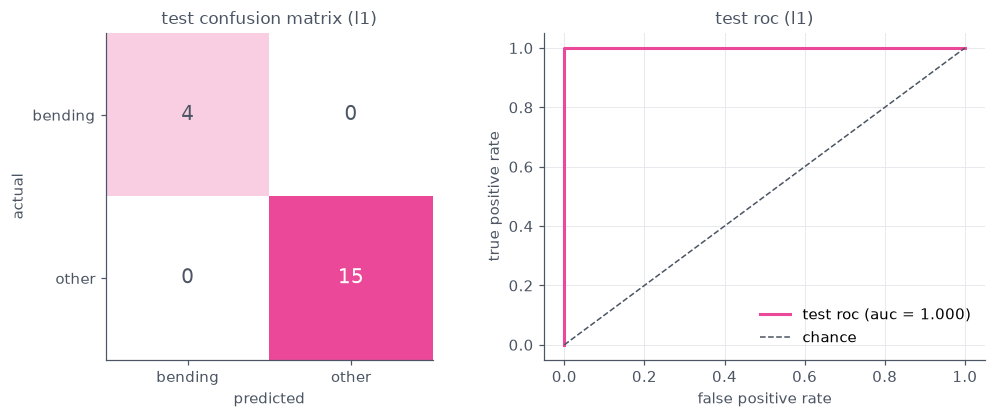

,pred bending,pred other
actual bending,4,0
actual other,0,15


In [16]:
# final l1 model on all 69 training rows at the winning (l, C)
l1_pipe = Pipeline([("vt", VarianceThreshold()), ("scaler", StandardScaler()),
                    ("lr", make_l1(best_C))])
l1_pipe.fit(X_by_l[best_l1_l], y_binary)

l1_names = l1_pipe[:-1].get_feature_names_out()
l1_nonzero = l1_names[l1_pipe[-1].coef_[0] != 0]
print(f"l1 keeps {len(l1_nonzero)} of {len(l1_names)} features (coefficients on the "
      f"standardized scale):\n  {list(l1_nonzero)}")

# cv metrics of the winning pair: out-of-fold accuracy, balanced accuracy, auc
oof_p = np.zeros(69)
fold_acc = []
for tr_idx, va_idx in CV5.split(X_by_l[best_l1_l], y_binary):
    pipe = Pipeline([("vt", VarianceThreshold()), ("scaler", StandardScaler()),
                     ("lr", make_l1(best_C))])
    pipe.fit(X_by_l[best_l1_l].iloc[tr_idx], y_binary[tr_idx])
    oof_p[va_idx] = pipe.predict_proba(X_by_l[best_l1_l].iloc[va_idx])[:, 1]
    fold_acc.append(accuracy_score(y_binary[va_idx], oof_p[va_idx] > 0.5))
l1_cv_acc = float(np.mean(fold_acc))
l1_bal_acc = balanced_accuracy_score(y_binary, oof_p > 0.5)
l1_cv_auc = auc(*roc_curve(y_binary, oof_p)[:2])
print(f"cv accuracy {l1_cv_acc:.3f} | cv balanced accuracy {l1_bal_acc:.3f} | "
      f"cv auc {l1_cv_auc:.3f}")

# test evaluation with identical segmentation
test_feats_l1 = extract_features(test_instances, n_segments=best_l1_l).drop(
    columns=["instance", "activity"])
assert list(test_feats_l1.columns) == list(X_by_l[best_l1_l].columns)
l1_test_pred = l1_pipe.predict(test_feats_l1)
l1_test_score = l1_pipe.predict_proba(test_feats_l1)[:, 1]
l1_test_acc = accuracy_score(y_test, l1_test_pred)
l1_test_auc = auc(*roc_curve(y_test, l1_test_score)[:2])
print(f"test accuracy {l1_test_acc:.3f} ({(y_test == l1_test_pred).sum()}/19) | "
      f"test auc {l1_test_auc:.3f}")

fig, (ax_cm, ax_roc) = plt.subplots(1, 2, figsize=(9.5, 3.9))
cm_arr = confusion_matrix(y_test, l1_test_pred, labels=[1, 0])
ax_cm.imshow(cm_arr, cmap=cmap_pink, vmin=0, vmax=cm_arr.max())
for r in range(2):
    for c in range(2):
        ax_cm.text(c, r, cm_arr[r, c], ha="center", va="center", fontsize=13,
                   color="white" if cm_arr[r, c] > cm_arr.max() / 2 else NEUTRAL)
ax_cm.set_xticks([0, 1], ["bending", "other"])
ax_cm.set_yticks([0, 1], ["bending", "other"])
ax_cm.set_xlabel("predicted")
ax_cm.set_ylabel("actual")
ax_cm.set_title("test confusion matrix (l1)")
ax_cm.grid(False)
fpr_l1, tpr_l1, _ = roc_curve(y_test, l1_test_score)
ax_roc.plot(fpr_l1, tpr_l1, color=PINK, linewidth=2,
            label=f"test roc (auc = {l1_test_auc:.3f})")
ax_roc.plot([0, 1], [0, 1], color=NEUTRAL, linewidth=1, linestyle="--", label="chance")
ax_roc.set_xlabel("false positive rate")
ax_roc.set_ylabel("true positive rate")
ax_roc.set_title("test roc (l1)")
ax_roc.legend(loc="lower right")
fig.tight_layout()
plt.show()

confusion_df(y_test, l1_test_pred)

## 2(b)ii L1 vs RFE

Both selectors on the same metrics: mean CV accuracy and out-of-fold AUC of
the winning configuration, then accuracy and AUC on the 19 test instances.

In [17]:
comparison = pd.DataFrame({
    "model": ["rfe (2(a)iii)", "l1 (2(b)i)"],
    "best l": [best_l, best_l1_l],
    "selection": [f"rfe, p = {best_p}", f"l1, C = {best_C:.3g}"],
    "features kept": [best_p, len(l1_nonzero)],
    "cv accuracy": [cv_acc, l1_cv_acc],
    "cv auc (oof)": [cv_auc, l1_cv_auc],
    "test accuracy": [test_acc, l1_test_acc],
    "test auc": [test_auc, l1_test_auc],
}).set_index("model")
comparison.round(3)

,best l,selection,features kept,cv accuracy,cv auc (oof),test accuracy,test auc
model,,,,,,,
rfe (2(a)iii),1,"rfe, p = 16",16,0.986,0.996,1.0,1.0
l1 (2(b)i),1,"l1, C = 2.15",8,0.971,0.981,1.0,1.0


**2(b)ii answer.** On cross-validated metrics the **RFE model performs
better**: mean CV accuracy 0.986 vs 0.971 and out-of-fold AUC 0.996 vs
0.981 (balanced accuracy 0.992 vs 0.889). On test both are perfect (accuracy
1.000, AUC 1.000), so the test set cannot separate them. **L1 is easier to
implement**: each (l, C, fold) needs one plain pipeline fit and the penalty
does the selection, while RFE needed a ranking run per fold, a top-p refit
for every p in the grid, and the elimination-order shortcut plus its
verification assert to stay affordable. L1 also lands on the sparser model
(8 of 40 features vs 16), and the left columns of its CV table show its
other convenient property: with a strong penalty (C up to about 0.013)
every coefficient is zeroed and the model falls back to the majority-class
baseline accuracy of 0.870, exactly as expected. With 19 test rows and both
models at 19/19, the CV numbers are the only basis for picking, and they
favor RFE on this data.

## 2(c)i multinomial L1 logistic regression, 7 classes

The classifier is now multinomial logistic regression with an L1 penalty over
all 7 activities. `solver = saga` is used because it is the solver that
combines the multinomial loss with L1; `liblinear` reduces multiclass
problems to one-vs-rest and therefore does not count as multinomial. The
same `Pipeline(VarianceThreshold, StandardScaler, LogisticRegression)` is fit
inside each training fold, jointly over l in 1..20 and the C grid below.

- **Cross-validation, and why 4 folds.** The handout asks for the best l in
  the same general manner as 2(b)i, that is, by cross-validated selection
  over l (and C) on the training set. bending2 has only four training
  observations, so stratified 5-fold CV cannot place a bending2 observation
  in every validation fold: with 5 folds, one validation fold necessarily
  contains no bending2 row at all. Every seven-class model therefore uses
  **stratified 4-fold CV** (`shuffle = True`, `random_state = 42`), which
  puts exactly one bending2 observation in each validation fold, and
  GaussianNB and MultinomialNB in 2(c)ii use the same 4 folds so their
  comparison is fair. Binary model selection in 2(a)iii and 2(b) keeps the
  usual stratified 5-fold CV, which the 9 bending training instances
  support.
- **The C grid.** The multinomial search uses C = {0.001, 0.0028, 0.0077,
  0.0215, 0.0599, 0.166, 0.464, 1.29, 3.59, 10} (10 log-spaced points from
  10^-3 to 10^1). This is deliberately **not** the binary grid of 2(b)i,
  which ran up to 100: saga did not converge within a practical iteration
  budget (max_iter = 10000) for C above 10 on the larger feature pools, so
  the grid is capped at 10 for convergence and runtime.
- **Near-ties.** A narrow winning cell can still have isolated grid points
  within 0.01 of it (the runner-up does not have to be a neighboring cell),
  so the search also reports how many (l, C) pairs lie within 0.01 of the
  best CV accuracy; differences of that size are not treated as meaningful.
- **Leakage control.** Variance filtering and standardization live inside the
  pipeline fit on the training folds only.
- **Tie-break rule:** highest mean CV accuracy, then smallest l, then
  smallest C.

**Definitions used below.** The multiclass confusion matrix C has entries
C[i, j] = number of test instances whose true class is i and that are
predicted as class j; diagonal = correct, off-diagonal = confusions. A
per-class ROC curve treats one class as positive and pools all others as
negative (one-vs-rest), scored by that class's predicted probability; its
AUC measures ranking quality for that class alone. The **micro-average AUC**
flattens all 7 x 19 (class, instance) pairs into one ROC, so frequent
classes dominate; the **macro-average AUC is the unweighted mean of the
seven per-class AUCs**, and it is computed directly as that mean. The plot
additionally shows the macro-averaged ROC curve (per-class curves pooled by
interpolation over a common false-positive-rate grid); its own area is a
different, descriptive quantity, reported separately and labeled as such.


In [18]:
y_multi = np.array([ACTIVITIES.index(a) for a in train_features["activity"]])
y_multi_test = np.array([ACTIVITIES.index(a) for a in
                         [i["activity"] for i in test_instances]])
assert y_multi.shape == (69,) and (y_multi == 0).sum() == 5 and (y_multi == 1).sum() == 4

# c grid capped at 10 for the multinomial search: larger C values did not
# converge within max_iter = 10000 on the biggest feature pools
MN_C_GRID = np.logspace(-3, 1, 10)


def make_mn(C):
    # saga: the only solver combining multinomial loss with l1
    return LogisticRegression(solver="saga", l1_ratio=1, C=C,
                              max_iter=10000, random_state=SEED)


def cv_mn(l, X, C):
    accs = []
    for tr_idx, va_idx in CV4.split(X, y_multi):
        pipe = Pipeline([("vt", VarianceThreshold()), ("scaler", StandardScaler()),
                         ("lr", make_mn(C))])
        pipe.fit(X.iloc[tr_idx], y_multi[tr_idx])
        accs.append(accuracy_score(y_multi[va_idx], pipe.predict(X.iloc[va_idx])))
    return float(np.mean(accs))


# the (l, C) grid is embarrassingly parallel; n_jobs = -1 uses every core and
# each task is deterministic (fixed folds, fixed solver seed)
grid = Parallel(n_jobs=-1)(
    delayed(cv_mn)(l, X_by_l[l], C) for l in range(1, MAX_L + 1) for C in MN_C_GRID)

mn_table = pd.DataFrame(np.asarray(grid).reshape(MAX_L, len(MN_C_GRID)),
                        index=range(1, MAX_L + 1),
                        columns=[f"{c:.3g}" for c in MN_C_GRID], dtype=float)
mn_table.index.name = "l"

best_mn_l, best_mn_C = max(((l, C) for l in mn_table.index for C in MN_C_GRID),
                           key=lambda lc: (mn_table.loc[lc[0], f"{lc[1]:.3g}"], -lc[0], -lc[1]))
flat = mn_table.stack()
near = flat[flat >= flat.max() - 0.01]
print(f"best multinomial l1 (l, C) = ({best_mn_l}, {best_mn_C:.3g}) with cv accuracy "
      f"{flat.max():.3f}")
print(f"cv near-ties: {len(near)} of {len(flat)} (l, C) pairs within 0.01 of the best; "
      f"their l values span {sorted(set(near.index.get_level_values('l')))}")
mn_table.round(3)

best multinomial l1 (l, C) = (2, 3.59) with cv accuracy 0.914
cv near-ties: 2 of 200 (l, C) pairs within 0.01 of the best; their l values span [1, 2]


,0.001,0.00278,0.00774,0.0215,0.0599,0.167,0.464,1.29,3.59,10
l,,,,,,,,,,
1,0.174,0.174,0.174,0.174,0.262,0.811,0.855,0.855,0.884,0.913
2,0.174,0.174,0.174,0.174,0.348,0.828,0.813,0.842,0.914,0.899
3,0.174,0.174,0.174,0.174,0.306,0.798,0.769,0.784,0.798,0.799
4,0.174,0.174,0.174,0.174,0.348,0.768,0.725,0.726,0.755,0.770
5,0.174,0.174,0.174,0.174,0.348,0.797,0.725,0.797,0.783,0.797
6,0.174,0.174,0.174,0.174,0.348,0.768,0.753,0.768,0.769,0.812
7,0.174,0.174,0.174,0.174,0.304,0.767,0.725,0.767,0.781,0.854
8,0.174,0.174,0.174,0.174,0.348,0.768,0.752,0.766,0.737,0.766
9,0.174,0.174,0.174,0.174,0.348,0.739,0.796,0.795,0.824,0.839


test error: 0.158 (3 of 19 misclassified)


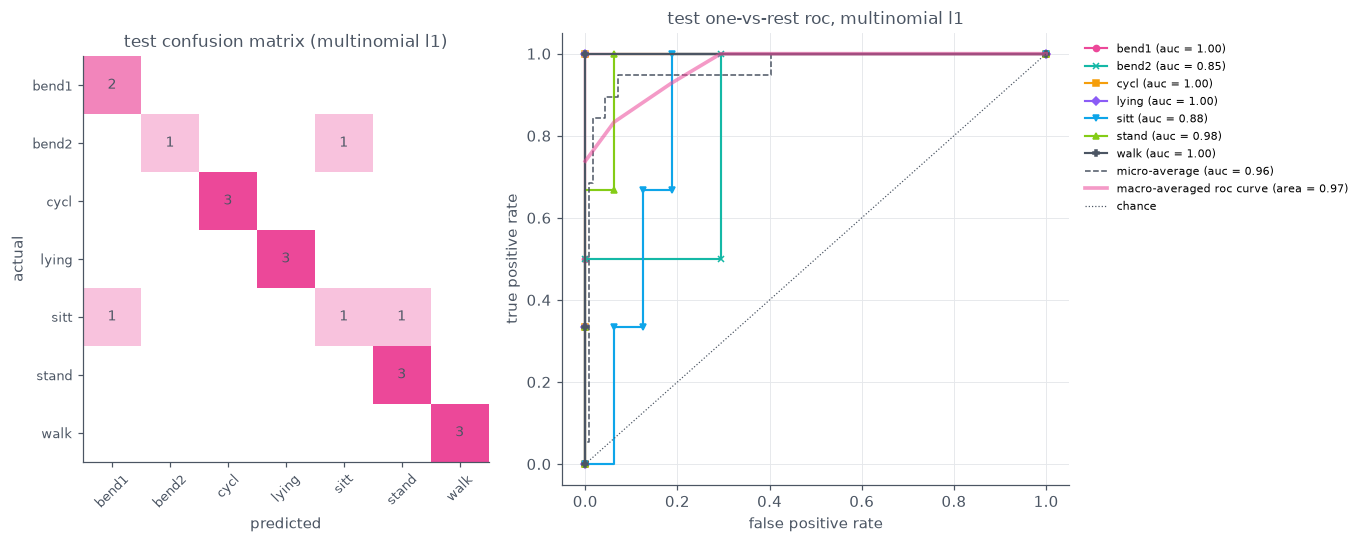

per-class one-vs-rest test auc with micro/macro averages:
                                     one-vs-rest auc
bend1                                          1.000
bend2                                          0.853
cycl                                           1.000
lying                                          1.000
sitt                                           0.875
stand                                          0.979
walk                                           1.000
micro-average                                  0.964
macro-average (mean of per-class)              0.958
area under macro-averaged roc curve            0.968


,pred bend1,pred bend2,pred cycl,pred lying,pred sitt,pred stand,pred walk
true bend1,2,0,0,0,0,0,0
true bend2,0,1,0,0,1,0,0
true cycl,0,0,3,0,0,0,0
true lying,0,0,0,3,0,0,0
true sitt,1,0,0,0,1,1,0
true stand,0,0,0,0,0,3,0
true walk,0,0,0,0,0,0,3


In [19]:
# final multinomial model at the winning (l, C), refit on all 69 training rows
mn_pipe = Pipeline([("vt", VarianceThreshold()), ("scaler", StandardScaler()),
                    ("lr", make_mn(best_mn_C))])
mn_pipe.fit(X_by_l[best_mn_l], y_multi)

test_feats_mn = extract_features(test_instances, n_segments=best_mn_l).drop(
    columns=["instance", "activity"])
assert list(test_feats_mn.columns) == list(X_by_l[best_mn_l].columns)
mn_test_pred = mn_pipe.predict(test_feats_mn)
mn_test_proba = mn_pipe.predict_proba(test_feats_mn)

mn_errors = int((y_multi_test != mn_test_pred).sum())
mn_test_err = 1 - accuracy_score(y_multi_test, mn_test_pred)
print(f"test error: {mn_test_err:.3f} ({mn_errors} of 19 misclassified)")

ACT_SHORT = ["bend1", "bend2", "cycl", "lying", "sitt", "stand", "walk"]
cm_arr = confusion_matrix(y_multi_test, mn_test_pred, labels=range(7))
cm_mn = pd.DataFrame(cm_arr,
                     index=[f"true {a}" for a in ACT_SHORT],
                     columns=[f"pred {a}" for a in ACT_SHORT])

# per-class one-vs-rest roc; micro/macro averages computed directly
Y_bin = label_binarize(y_multi_test, classes=range(7))
roc_curves = {}
for k, name in enumerate(ACT_SHORT):
    fpr_k, tpr_k, _ = roc_curve(Y_bin[:, k], mn_test_proba[:, k])
    roc_curves[name] = (fpr_k, tpr_k, auc(fpr_k, tpr_k))
micro_auc = float(roc_auc_score(Y_bin, mn_test_proba, average="micro", multi_class="ovr"))
macro_auc = float(np.mean([v[2] for v in roc_curves.values()]))
macro_check = float(roc_auc_score(Y_bin, mn_test_proba, average="macro", multi_class="ovr"))
assert abs(macro_auc - macro_check) < 1e-10  # the mean of the 7 per-class aucs

# separate descriptive quantity: the area under the interpolated
# macro-averaged roc curve (not the mean of the per-class aucs)
all_fpr = np.unique(np.concatenate([v[0] for v in roc_curves.values()]))
mean_tpr = np.zeros_like(all_fpr)
for fpr_k, tpr_k, _ in roc_curves.values():
    mean_tpr += np.interp(all_fpr, fpr_k, tpr_k)
mean_tpr /= len(ACT_SHORT)
macro_curve_auc = auc(all_fpr, mean_tpr)

auc_table = pd.DataFrame({"one-vs-rest auc": {name: v[2] for name, v in roc_curves.items()}})
auc_table.loc["micro-average"] = micro_auc
auc_table.loc["macro-average (mean of per-class)"] = macro_auc
auc_table.loc["area under macro-averaged roc curve"] = macro_curve_auc

CLASS_COLORS = [PINK, TEAL, "#F59E0B", "#8B5CF6", "#0EA5E9", "#84CC16", NEUTRAL]
CLASS_MARKERS = ["o", "x", "s", "D", "v", "^", "P"]
fig, (ax_cm, ax_roc) = plt.subplots(1, 2, figsize=(12.5, 5.2), width_ratios=[1, 1.25])
ax_cm.imshow(cm_arr, cmap=cmap_pink, vmin=0)
ax_cm.set_xticks(range(7), ACT_SHORT, rotation=45, fontsize=8.5)
ax_cm.set_yticks(range(7), ACT_SHORT, fontsize=8.5)
for r in range(7):
    for col in range(7):
        if cm_arr[r, col]:
            ax_cm.text(col, r, cm_arr[r, col], ha="center", va="center", fontsize=9,
                       color="white" if cm_arr[r, col] > 6 else NEUTRAL)
ax_cm.set_xlabel("predicted")
ax_cm.set_ylabel("actual")
ax_cm.set_title("test confusion matrix (multinomial l1)")
ax_cm.grid(False)
for k, name in enumerate(ACT_SHORT):
    fpr_k, tpr_k, auc_k = roc_curves[name]
    ax_roc.plot(fpr_k, tpr_k, color=CLASS_COLORS[k], linewidth=1.4,
                marker=CLASS_MARKERS[k], markevery=0.15, markersize=4,
                label=f"{name} (auc = {auc_k:.2f})")
fpr_mi, tpr_mi, _ = roc_curve(Y_bin.ravel(), mn_test_proba.ravel())
ax_roc.plot(fpr_mi, tpr_mi, color=NEUTRAL, linewidth=1, linestyle="--",
            label=f"micro-average (auc = {micro_auc:.2f})")
ax_roc.plot(all_fpr, mean_tpr, color=PINK, linewidth=2.4, alpha=0.55,
            label=f"macro-averaged roc curve (area = {macro_curve_auc:.2f})")
ax_roc.plot([0, 1], [0, 1], color=NEUTRAL, linewidth=0.8, linestyle=":", label="chance")
ax_roc.set_xlabel("false positive rate")
ax_roc.set_ylabel("true positive rate")
ax_roc.set_title("test one-vs-rest roc, multinomial l1")
ax_roc.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=7.5)
fig.tight_layout()
plt.show()

print("per-class one-vs-rest test auc with micro/macro averages:")
print(auc_table.round(3).to_string())

cm_mn

**2(c)i answer.** The multinomial L1 search selects **l = 2 and C = 3.59**
with a mean 4-fold CV accuracy of **0.914**. That cell is a relatively
narrow peak rather than a broad plateau: the runner-up (l = 1, C = 10) at
0.913 is a near-tie sitting on the upper boundary of the tested C grid, and
2 of the 200 (l, C) pairs lie within 0.01 of the best, so differences of
that size are not treated as meaningful. On the 19
test instances the model makes **3 errors (test error 0.158)**: one bending2
instance is predicted sitting, one sitting instance is predicted bending1,
and one sitting instance is predicted standing; every bending1, cycling,
lying, standing, and walking instance is classified correctly (see the
confusion matrix). The per-class one-vs-rest test AUCs are 1.000 for bend1,
cycling, lying, and walking, 0.979 for standing, 0.875 for sitting, and
0.853 for bend2, whose curve is coarse because bend2 has only 2 test
instances. The **micro-average AUC is 0.964** and the **macro-average AUC,
the unweighted mean of the seven per-class AUCs, is 0.958**; the plot also
shows the macro-averaged ROC curve, whose own area (0.968) is reported
separately as a different descriptive quantity.

## 2(c)ii naive Bayes: Gaussian and multinomial

Both naive Bayes variants assume features are independent given the class;
they differ in the per-feature likelihood. **GaussianNB** models each feature
as Gaussian per class and works on any real-valued input, so its pipeline is
`VarianceThreshold -> GaussianNB`. **MultinomialNB** models nonnegative
count-like vectors, so it needs nonnegative features: every one of the 7
statistics (min, max, mean, median, std, q1, q3) of the nonnegative sensor
series is nonnegative, which is asserted below on all feature matrices; were
that ever false, the correct fix would be a `MinMaxScaler` fit inside each
fold (never standardization, which creates negatives). l is selected for each
variant separately by the same stratified 4-fold CV used in 2(c)i (every
validation fold holds one bending2 row; ties toward the smallest l).

In [20]:
def cv_nb(l, X, make_pipe):
    accs = []
    for tr_idx, va_idx in CV4.split(X, y_multi):
        pipe = make_pipe()
        pipe.fit(X.iloc[tr_idx], y_multi[tr_idx])
        accs.append(accuracy_score(y_multi[va_idx], pipe.predict(X.iloc[va_idx])))
    return float(np.mean(accs))


gnb_accs = {l: cv_nb(l, X_by_l[l],
                     lambda: Pipeline([("vt", VarianceThreshold()), ("nb", GaussianNB())]))
            for l in range(1, MAX_L + 1)}
best_gnb_l = max(gnb_accs, key=lambda l: (gnb_accs[l], -l))
print(f"gaussian nb: best l = {best_gnb_l}, cv accuracy {gnb_accs[best_gnb_l]:.3f}")

# nonnegativity check for multinomial nb across every l
assert all(X.to_numpy().min() >= 0 for X in X_by_l.values()), "negative features found"
print("all segmented feature matrices are nonnegative: multinomial nb can use them raw")

mnb_accs = {l: cv_nb(l, X_by_l[l],
                     lambda: Pipeline([("vt", VarianceThreshold()), ("nb", MultinomialNB())]))
            for l in range(1, MAX_L + 1)}
best_mnb_l = max(mnb_accs, key=lambda l: (mnb_accs[l], -l))
print(f"multinomial nb: best l = {best_mnb_l}, cv accuracy {mnb_accs[best_mnb_l]:.3f}")

pd.DataFrame({"gaussian nb cv accuracy": gnb_accs,
              "multinomial nb cv accuracy": mnb_accs}).round(3)

gaussian nb: best l = 1, cv accuracy 0.856
all segmented feature matrices are nonnegative: multinomial nb can use them raw


multinomial nb: best l = 1, cv accuracy 0.840


,gaussian nb cv accuracy,multinomial nb cv accuracy
1,0.856,0.840
2,0.797,0.810
3,0.694,0.781
4,0.665,0.796
5,0.564,0.810
6,0.695,0.795
7,0.680,0.810
8,0.694,0.796
9,0.608,0.782
10,0.636,0.796


gaussian nb:    test error 0.105 (2 of 19)
multinomial nb: test error 0.105 (2 of 19)


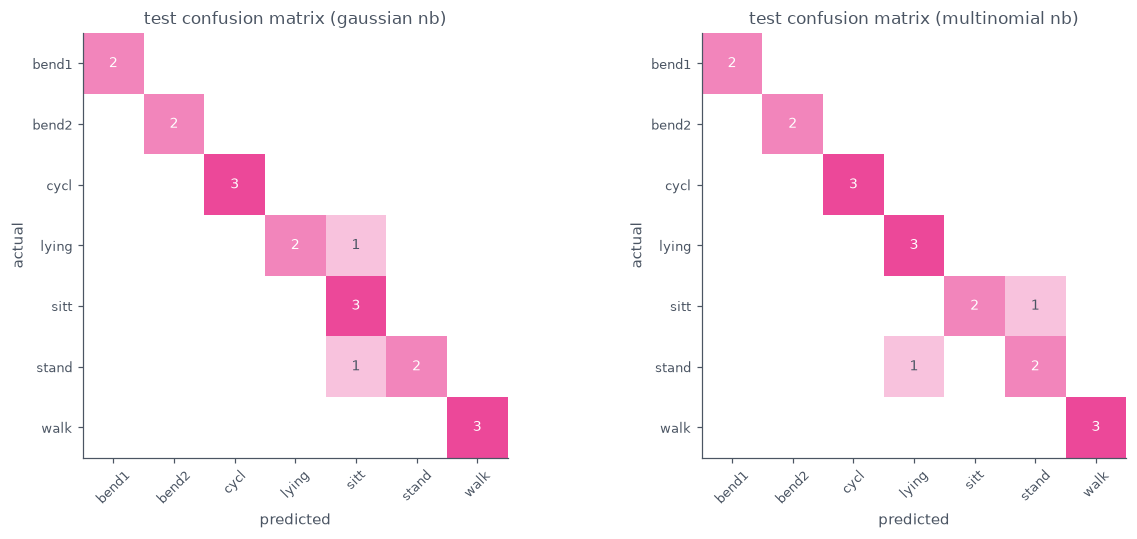

,gaussian nb,multinomial nb,true,gaussian ok,multinomial ok
bending1/dataset1,0,0,bending1,True,True
bending1/dataset2,0,0,bending1,True,True
bending2/dataset1,1,1,bending2,True,True
bending2/dataset2,1,1,bending2,True,True
cycling/dataset1,2,2,cycling,True,True
cycling/dataset2,2,2,cycling,True,True
cycling/dataset3,2,2,cycling,True,True
lying/dataset1,3,3,lying,True,True
lying/dataset2,4,3,lying,False,True
lying/dataset3,3,3,lying,True,True


In [21]:
def eval_nb(best_l, cls):
    pipe = Pipeline([("vt", VarianceThreshold()), ("nb", cls())])
    pipe.fit(X_by_l[best_l], y_multi)
    test_feats = extract_features(test_instances, n_segments=best_l).drop(
        columns=["instance", "activity"])
    assert list(test_feats.columns) == list(X_by_l[best_l].columns)
    pred = pipe.predict(test_feats)
    return pipe, pred, test_feats


gnb_pipe, gnb_pred, _ = eval_nb(best_gnb_l, GaussianNB)
mnb_pipe, mnb_pred, _ = eval_nb(best_mnb_l, MultinomialNB)
gnb_errors = int((y_multi_test != gnb_pred).sum())
mnb_errors = int((y_multi_test != mnb_pred).sum())
gnb_cm = pd.DataFrame(confusion_matrix(y_multi_test, gnb_pred, labels=range(7)),
                      index=ACT_SHORT, columns=ACT_SHORT)
mnb_cm = pd.DataFrame(confusion_matrix(y_multi_test, mnb_pred, labels=range(7)),
                      index=ACT_SHORT, columns=ACT_SHORT)
print(f"gaussian nb:    test error {1 - accuracy_score(y_multi_test, gnb_pred):.3f} "
      f"({gnb_errors} of 19)")
print(f"multinomial nb: test error {1 - accuracy_score(y_multi_test, mnb_pred):.3f} "
      f"({mnb_errors} of 19)")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.0))
for ax, (pred, name) in zip(axes, [(gnb_pred, "gaussian nb"), (mnb_pred, "multinomial nb")]):
    cm = confusion_matrix(y_multi_test, pred, labels=range(7))
    ax.imshow(cm, cmap=cmap_pink, vmin=0, vmax=max(cm.max(), 1))
    for r in range(7):
        for col in range(7):
            if cm[r, col]:
                ax.text(col, r, cm[r, col], ha="center", va="center", fontsize=9,
                        color="white" if cm[r, col] > cm.max() / 2 else NEUTRAL)
    ax.set_xticks(range(7), ACT_SHORT, rotation=45, fontsize=8.5)
    ax.set_yticks(range(7), ACT_SHORT, fontsize=8.5)
    ax.set_xlabel("predicted")
    ax.set_ylabel("actual")
    ax.set_title(f"test confusion matrix ({name})")
    ax.grid(False)
fig.tight_layout()
plt.show()

pd.DataFrame({"gaussian nb": gnb_pred, "multinomial nb": mnb_pred,
              "true": [ACTIVITIES[k] for k in y_multi_test],
              "gaussian ok": gnb_pred == y_multi_test,
              "multinomial ok": mnb_pred == y_multi_test},
             index=[i["id"] for i in test_instances])

**2(c)ii answer.** **GaussianNB** selects l = 1 with CV accuracy **0.856**
and makes **2 test errors (0.105)**: lying/dataset2 is predicted sitting and
standing/dataset1 is predicted sitting. **MultinomialNB** also selects l = 1,
with CV accuracy **0.840** and the same test error count, **2 of 19 (0.105)**:
sitting/dataset1 is predicted standing and standing/dataset1 is predicted
lying. Both variants confine their mistakes to the three static postures
(lying, sitting, standing), as the confusion matrices and the per-instance
table show; both classify every bending, cycling, and walking instance
correctly.

## 2(c)iii which method performs best?

The three multiclass methods side by side, plus the evidence about feature
dependence that the discussion needs: pairwise correlations among the 42
unsegmented training features.

In [22]:
mn_cv_acc = float(mn_table.loc[best_mn_l, f"{best_mn_C:.3g}"])
summary = pd.DataFrame({
    "model": ["multinomial l1 (2(c)i)", "gaussian nb (2(c)ii)", "multinomial nb (2(c)ii)"],
    "best l": [best_mn_l, best_gnb_l, best_mnb_l],
    "cv accuracy": [mn_cv_acc, gnb_accs[best_gnb_l], mnb_accs[best_mnb_l]],
    "test errors of 19": [mn_errors, gnb_errors, mnb_errors],
    "test error rate": [1 - accuracy_score(y_multi_test, mn_test_pred),
                        1 - accuracy_score(y_multi_test, gnb_pred),
                        1 - accuracy_score(y_multi_test, mnb_pred)],
}).set_index("model")
print(summary.round(3).to_string())

# constant columns (dropped by the variance threshold in every pipeline)
# have undefined correlation, so they are excluded here
X1 = X_by_l[1].loc[:, X_by_l[1].std() > 0]
corr_abs = X1.corr().abs().to_numpy()
pairs = corr_abs[np.triu_indices_from(corr_abs, k=1)]
print(f"\npairwise |correlation| among the {X1.shape[1]} non-constant training "
      f"features (l = 1): max = {pairs.max():.3f}; {int((pairs > 0.9).sum())} pairs above 0.9; "
      f"{int((pairs > 0.8).sum())} pairs above 0.8")

# secondary sensitivity only (not part of the primary analysis): the handout
# asks for selection in the same general manner as 2(b)i, which uses 5 folds;
# the already-selected configurations are re-scored under stratified 5-fold
# cv so the fold choice can be checked. 5 folds force one validation fold to
# contain no bending2 row, hence the single expected user warning filtered
# here, scoped to these three rescoring runs
def fold_cv(X, make_pipe, cv):
    accs = []
    for tr_idx, va_idx in cv.split(X, y_multi):
        pipe = make_pipe()
        pipe.fit(X.iloc[tr_idx], y_multi[tr_idx])
        accs.append(accuracy_score(y_multi[va_idx], pipe.predict(X.iloc[va_idx])))
    return float(np.mean(accs))


with warnings.catch_warnings():
    warnings.filterwarnings("ignore", category=UserWarning,
                            message="The least populated class in y has only 4 members.*")
    sens = {
        "multinomial l1 (l = 2, C = 3.59)": fold_cv(
            X_by_l[best_mn_l],
            lambda: Pipeline([("vt", VarianceThreshold()), ("scaler", StandardScaler()),
                              ("lr", make_mn(best_mn_C))]), CV5),
        "gaussian nb (l = 1)": fold_cv(
            X_by_l[best_gnb_l],
            lambda: Pipeline([("vt", VarianceThreshold()), ("nb", GaussianNB())]), CV5),
        "multinomial nb (l = 1)": fold_cv(
            X_by_l[best_mnb_l],
            lambda: Pipeline([("vt", VarianceThreshold()), ("nb", MultinomialNB())]), CV5),
    }
print("\nsecondary sensitivity only - selected configurations re-scored under")
print("stratified 5-fold cv; the primary multiclass analysis stays 4-fold:")
print(pd.Series(sens).round(3).to_string())

                         best l  cv accuracy  test errors of 19  test error rate
model                                                                           
multinomial l1 (2(c)i)        2        0.914                  3            0.158
gaussian nb (2(c)ii)          1        0.856                  2            0.105
multinomial nb (2(c)ii)       1        0.840                  2            0.105

pairwise |correlation| among the 40 non-constant training features (l = 1): max = 0.999; 114 pairs above 0.9; 160 pairs above 0.8



secondary sensitivity only - selected configurations re-scored under
stratified 5-fold cv; the primary multiclass analysis stays 4-fold:
multinomial l1 (l = 2, C = 3.59)    0.914
gaussian nb (l = 1)                 0.857
multinomial nb (l = 1)              0.855


**2(c)iii answer.** Weighing all the evidence in this notebook,
**multinomial L1 logistic regression is the better method for this problem,
with the explicit caveat that its margin rests on cross-validation rather
than on the small test set.** The two sources of evidence point in different
directions and both are reported. On CV accuracy, multinomial L1 is clearly
stronger: 0.914 against 0.856 (GaussianNB) and 0.840 (MultinomialNB). On the
test set, the two naive Bayes models make one fewer error: 2 of 19 versus 3
of 19. With only 19 test instances a one-error difference is weak evidence;
a single instance moves the test error rate by 5.3 points, and the test
ranking could flip under a different split. Two structural cautions also
apply to the raw CV comparison. First, the hyperparameter searches have
different sizes (200 (l, C) pairs for multinomial L1 versus 20 l values per
naive Bayes variant), so the winning CV scores carry different amounts of
selection bias; a larger search finds higher maxima partly by chance, and
the near-tie counts printed with each search show the runners-up are close.
Second, the substantive evidence favors the logistic model's assumptions:
the correlation check above found 114 of the 780 feature pairs above 0.9 in
absolute correlation, which violates the conditional-independence assumption
both naive Bayes classifiers rely on, and MultinomialNB's multinomial
likelihood is designed for nonnegative count-like inputs rather than these
continuous summary features, a misspecified likelihood for this data. That
the naive Bayes models remain competitive on test despite the violated
assumptions, while trailing by about six points of CV accuracy, is the
pattern the theory predicts. A secondary 5-fold
rescoring of the three already-selected configurations (printed above,
clearly labeled as secondary) leaves the ordering unchanged, 0.914 against
0.857 and 0.855. Given the disagreement between the stronger CV evidence
and the weaker test evidence, the defensible conclusion is that multinomial
L1 is the best-supported choice here; the test set alone would have picked
a naive Bayes model, and that disagreement is acknowledged rather than
resolved.

## 3. ISLR 4.8.3: the Bayes classifier under a one-feature QDA model

**Setup** (ISLR exercise 4.8.3). There is one feature and K classes; within
class k the observations are drawn from a normal distribution with
class-specific mean and class-specific variance, X | Y = k ~ N(mu_k, sigma_k^2),
and class prior pi_k. The claim to verify: the Bayes classifier is quadratic,
not linear.

**Derivation.** The Bayes classifier assigns x to the class with the largest
posterior p_k(x) = pi_k f_k(x) / (pi_1 f_1(x) + ... + pi_K f_K(x)). The
denominator does not depend on k, so classification is by

    argmax_k  pi_k f_k(x).

With the normal density

    f_k(x) = (1 / sqrt(2 pi sigma_k^2)) exp(-(x - mu_k)^2 / (2 sigma_k^2)),

taking logs and dropping terms that do not involve k gives the discriminant
score

    delta_k(x) = log pi_k - (1/2) log sigma_k^2 - (x - mu_k)^2 / (2 sigma_k^2)
               = -x^2 / (2 sigma_k^2) + mu_k x / sigma_k^2 - mu_k^2 / (2 sigma_k^2)
                 - (1/2) log sigma_k^2 + log pi_k,

which is the required form (the constant -1/2 log(2 pi) is omitted).

**Quadratic, not linear.** The coefficient of x^2 in delta_k(x) is
-1 / (2 sigma_k^2), and it depends on k. Setting two discriminant scores
equal gives the decision boundary between classes k and l:

    delta_k(x) = delta_l(x)  <=>  a x^2 + b x + c = 0,

with

    a = (1/2) (1/sigma_l^2 - 1/sigma_k^2),
    b = mu_k / sigma_k^2 - mu_l / sigma_l^2,
    c = mu_l^2 / (2 sigma_l^2) - mu_k^2 / (2 sigma_k^2)
        + (1/2) log(sigma_l^2 / sigma_k^2) + log(pi_k / pi_l).

Whenever sigma_k^2 != sigma_l^2, a != 0 and the boundary is given by the
roots of a genuine quadratic: up to two decision points between a pair of
classes. The class that maximizes delta_k(x) changes at those points, so the
Bayes classifier is quadratic (in one dimension, a parabola's crossings).

**Why equal variances recover linearity.** If sigma_k^2 = sigma_l^2 =
sigma^2, then a = 0: the x^2 terms cancel and each score reduces to

    delta_k(x) = mu_k x / sigma^2 - mu_k^2 / (2 sigma^2) + log pi_k,

which is linear in x, exactly the linear discriminant of LDA (ISLR section
4.4.1). Class-specific variances are therefore the only reason the QDA
boundary is quadratic; the quadratic term in x is what they buy.

## 4. ISLR 4.8.7: dividend prediction by Bayes' theorem

**Setup** (ISLR exercise 4.8.7). A stock issues a dividend ("Yes") with prior
probability pi_yes = 0.8, so pi_no = 0.2. Given the class, last year's
percent profit X is normal with common variance 36: X | Yes ~ N(10, 36) and
X | No ~ N(0, 36). Predict P(Yes | X = 4) for a company with X = 4.

**Bayes' theorem.** With sigma = 6,

    P(Yes | X = 4) = pi_yes f_yes(4) / (pi_yes f_yes(4) + pi_no f_no(4)),

    f_yes(4) = (1 / (6 sqrt(2 pi))) exp(-(4 - 10)^2 / (2 * 36))
             = (1 / (6 sqrt(2 pi))) exp(-1/2)   ~= 0.0403,
    f_no(4)  = (1 / (6 sqrt(2 pi))) exp(-(4 - 0)^2 / (2 * 36))
             = (1 / (6 sqrt(2 pi))) exp(-2/9)   ~= 0.0532,

    P(Yes | X = 4) = (0.8 * 0.0403) / (0.8 * 0.0403 + 0.2 * 0.0532)
                   ~= 0.0323 / 0.0429
                   ~= 0.7519.

The posterior is about **0.7519 > 0.5**, so the company is classified as
**Yes** (it will issue a dividend). The code cell below confirms the two
densities and the posterior numerically.

In [23]:
# numerical check of the hand calculation above
pi_yes, pi_no = 0.8, 0.2
f_yes = norm.pdf(4, loc=10, scale=6)
f_no = norm.pdf(4, loc=0, scale=6)
posterior = pi_yes * f_yes / (pi_yes * f_yes + pi_no * f_no)
print(f"f(4 | yes) = {f_yes:.4f}   f(4 | no) = {f_no:.4f}")
print(f"P(yes | X = 4) = {posterior:.4f} -> classify "
      f"{'Yes' if posterior > 0.5 else 'No'}")

f(4 | yes) = 0.0403   f(4 | no) = 0.0532
P(yes | X = 4) = 0.7519 -> classify Yes


## 5. references

1. G. James, D. Witten, T. Hastie, and R. Tibshirani. *An Introduction to
   Statistical Learning, with Applications in R*, 2nd edition, Springer,
   2021 (freely available at statlearning.com): chapter 4; section 4.3
   (logistic regression), section 4.4 (generative models for classification,
   including the linear discriminant used in exercise 4.8.3), and the
   chapter-4 exercises in section 4.8 (4.8.3 and 4.8.7).
2. T. Hastie, R. Tibshirani, and J. Friedman. *The Elements of Statistical
   Learning*, 2nd edition, Springer, 2009: section 4.4 (logistic
   regression), including the discussion of case-control (retrospective)
   sampling, in which the fitted intercept shifts while the slopes are
   unchanged; the basis of the intercept correction in 2(a)vii.
3. scikit-learn 1.9.1 documentation, scikit-learn.org:
   [`RFE`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.RFE.html),
   [`LogisticRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html),
   [`StratifiedKFold`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html),
   [`GaussianNB`](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html),
   [`MultinomialNB`](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.MultinomialNB.html).
4. statsmodels 0.15.0 documentation: statsmodels.org, `statsmodels.api.Logit`
   (the classical unpenalized logit used for the coefficient table in 2(a)iv).
5. SciPy 1.18.1 documentation: docs.scipy.org, `scipy.stats.norm` (the normal
   density check in ISLR 4.8.7).